In [ ]:
# ── Bucket-scoped output config (added by refactor) ─────────────────────
from pathlib import Path

def _find_project_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'data_preparation').exists() and (p / 'code').exists():
            return p
    raise RuntimeError('Cannot find project root')

BRAND_BUCKET = 'women_top1_dream_pairs'   # ← change per bucket run
PROJECT_ROOT = _find_project_root()
DATA_ROOT    = PROJECT_ROOT / 'data' / BRAND_BUCKET
ANALYSIS_DIR = DATA_ROOT / 'analysis_datasets'
KEY_DIR      = DATA_ROOT / 'keys'
DATA_DIR     = DATA_ROOT / 'amzn_shoes_monthly_diffs_ffill_fixed_splits'
PRED_DIR     = DATA_ROOT / 'predictions'
OUTPUT_DIR   = DATA_ROOT / 'output' / 'evaluation_final_all'
IMG_DIR      = PROJECT_ROOT / 'data' / 'images'   # shared (ASIN-unique)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'BRAND_BUCKET : {BRAND_BUCKET}')
print(f'OUTPUT_DIR   : {OUTPUT_DIR}')

In [1]:
!pip install doubleml lightning linearmodels -q
print('✅ doubleml, lightning, linearmodels installed')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 603.5/603.5 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 848.4/848.4 kB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 111.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.2/852.2 kB 63.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 513.1/513.1 kB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.6 MB/s eta 0:00:00
✅ doubleml, lightning, linearmodels insta

# Notebook 04 FINAL — DoubleML Evaluation: Price Elasticity of Demand
# Final version: Delta + Neighbor Prices + ϑ Conversion to Demand Elasticity

**Replication of Bach et al. (2025) — Adventures in Demand Analysis Using AI**
Applied to: Amazon Women's Shoes (Size 8)

---

## What Changed in This Version

**Revision 1 — Delta Variables (previous fix):**
Switched outcome/treatment from levels (Q_t, P_bb_t) to first differences
(Delta_Q_t, Delta_P_bb_t) to remove the 0.933 lag suppression problem.
Result: ATE moved from -0.066 to -0.094.

**Revision 2 — Neighbor/Competitor Prices (this version):**
Added neighbor_price_t and Delta_neighbor_price_t as controls.
For each ASIN, we compute the mean price of its top-10 most similar
products (by embedding cosine similarity) at each time period.

Why this helps (Bach et al. 2025, Appendix C):
- Competitor price changes are correlated with our price (shared market)
- But do not directly cause our product's demand (exogenous variation)
- Gives DoubleML IV-like price variation to identify theta more accurately

Expected improvement: ATE closer to -0.2 to -0.5

---

## Model Specification

```
Delta_Q_it = θ · Delta_P_it + g(X_it) + ε_it
```
- Outcome Y = Delta_Q_t
- Treatment D = Delta_P_bb_t
- Controls X = embeddings + tabular + neighbor_price_t + Delta_neighbor_price_t
- window=28 kept unchanged


In [ ]:
import os
import datasets
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score
from sklearn.metrics.pairwise import cosine_similarity  # ← ADDED for neighbor prices

import doubleml as dml

from utils.utils_data2 import (
    get_cis,
    generate_basis,
    generate_interactions,
)

from utils.utils_models import (
    iv_model,
    lin_model,
    lin_model_cate,
    summarize_lin_model,
    summarize_dml,
    chi2_test,
    predict_cate,
)
import warnings
warnings.filterwarnings("ignore")

palette = sns.color_palette("colorblind")

confidence_level = 0.9
ci_level_name, ci_names = get_cis(confidence_level)

output_dir = str(OUTPUT_DIR)
Path(output_dir).mkdir(parents=True, exist_ok=True)


In [5]:
txt_only = False
include_embeddings = True
dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
df_full_train = pd.read_csv(ANALYSIS_DIR / f"{dataframe_name}_train.zip")
df_full_val = pd.read_csv(ANALYSIS_DIR / f"{dataframe_name}_val.zip")

columns_to_drop = [
    "Q_t-2",
    "P_bb_t-2",
    "REVIEW_COUNT_t-2",
    "RATING_t-2",
    "pred_ml_l_lag_1",
    "pred_ml_m_lag_1",
]


df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

Dummy subcat names: ['Other', 'Fashion Sneakers', 'Ballet & Dance', 'Walking', 'Flats', 'Mules & Clogs', 'Ankle & Bootie', 'Pumps', 'Road Running', 'Loafers & Slip-Ons', 'Heeled Sandals']
All time steps: ['2025-04-28', '2025-05-26', '2025-06-23', '2025-07-21', '2025-08-18', '2025-09-15', '2025-10-13', '2025-11-10', '2025-12-08', '2026-01-05', '2026-02-02', '2026-03-02']


Index(['ASIN', 'date', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING', 'New Offer Count: Current',
       ...
       'REVIEW_COUNT_t-1', 'RATING_t-1', 'Delta_Q_t', 'Delta_P_bb_t',
       'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff', 'pred_ml_m_diff',
       'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1'],
      dtype='object', length=330)

In [6]:
print(dataframe_name)

dataset_txt_only_False_embeddings_True


In [7]:
print(df_full_val.shape)
print(df_full_train.shape)

(30888, 330)
(30876, 330)


In [ ]:
df_full_val[["ASIN", "date"]].to_csv(str(OUTPUT_DIR / "subset_val_keys.csv"), index=False)
df_full_train[["ASIN", "date"]].to_csv(str(OUTPUT_DIR / "subset_train_keys.csv"), index=False)

In [9]:
df_full_val.isna().sum()

,0
ASIN,0
date,0
Q_t,0
PRICE,0
P_bb_t,0
...,...
pred_ml_m,0
pred_ml_l_diff,0
pred_ml_m_diff,0
pred_ml_l_diff_lag_1,0


In [10]:
df_full_train["date"].unique()

array(['2025-04-28', '2025-05-26', '2025-06-23', '2025-07-21',
       '2025-08-18', '2025-09-15', '2025-10-13', '2025-11-10',
       '2025-12-08', '2026-01-05', '2026-02-02', '2026-03-02'],
      dtype=object)

In [11]:
df_full_val["date"].unique()

array(['2025-04-28', '2025-05-26', '2025-06-23', '2025-07-21',
       '2025-08-18', '2025-09-15', '2025-10-13', '2025-11-10',
       '2025-12-08', '2026-01-05', '2026-02-02', '2026-03-02'],
      dtype=object)

In [12]:
df_full_train["ASIN"].nunique()

2573

In [13]:
df_full_val["ASIN"].nunique()

2574

In [14]:
from datetime import datetime

date_objects = [datetime.strptime(date, "%Y-%m-%d") for date in all_time_steps]

# Calculate the difference in days between consecutive dates
date_differences = [
    (date_objects[i + 1] - date_objects[i]).days for i in range(len(date_objects) - 1)
]

# Print the differences
print(date_differences)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Variable Definitions (Revised — Delta + Neighbor Prices)

| Variable | Description | Role in model |
|---|---|---|
| `Delta_Q_t` | Q_t − Q_t-1 — change in log sales rank | **Outcome Y** |
| `Delta_P_bb_t` | P_bb_t − P_bb_t-1 — change in log buybox price | **Treatment D** |
| `neighbor_price_t` | Mean price of top-k similar ASINs at time t | **New control** |
| `Delta_neighbor_price_t` | Change in neighbor price vs last period | **New control** |
| `emb_0...255` | 256-dim multimodal embedding (txt+img+tab) | Controls X |
| `similarity_cluster_0...4` | Cosine similarity to 5 KMeans centroids | CATE basis |
| `RATING_t-1`, `REVIEW_COUNT_t-1` | Lagged product quality signals | Controls X |
| `dummy_subcat_*` | Subcategory fixed effects | Controls X |
| `dummy_time_*` | Time fixed effects (28-day periods) | Controls X |

**Why neighbor prices help:**
Bach et al. (2025) Appendix C shows that adding substitute/competitor prices
strengthens DoubleML identification. A neighbor's price change is correlated
with our product's price (shared market conditions) but does not directly
cause our product's demand — making it an IV-like control that adds
exogenous price variation for DoubleML to work with.

**Removed from controls:**
- ~~`Q_t-1`~~ — was causing 0.933 lag suppression
- ~~`P_bb_t-1`~~ — already embedded in Delta_P_bb_t

**window=28 kept unchanged.**


In [15]:
n_lags = 1

# ── REVISION v2: Delta variables + Neighbor Prices ────────────────────────
# outcome = Delta_Q_t, treatment = Delta_P_bb_t (from previous revision)
# NEW: compute neighbor/competitor prices from embedding similarity
# REFERENCE: Bach et al. (2025) Appendix C — substitute prices improve ATE
# ─────────────────────────────────────────────────────────────────────────

outcome        = ["Delta_Q_t"]     # REVISED: first difference of quantity
base_treatment = ["Delta_P_bb_t"]  # REVISED: first difference of price

# lag_1_vars kept for reference only — NOT used in PLR controls
lag_1_vars = ["Q_t-1", "P_bb_t-1"]

dummy_time_steps = all_time_steps[n_lags:]

all_dummy_controls = (
    dummy_subcat_names
    + dummy_time_steps
    + [
        "Lightning Deals: Upcoming Deal",
        "Buy Box: Is FBA",
    ]
)
dummy_baselines = [dummy_time_steps[0], "Residual"]
dummy_time_steps_wo_baseline = [t for t in dummy_time_steps if t not in dummy_baselines]
dummy_controls = [t for t in all_dummy_controls if t not in dummy_baselines]

cont_controls = [
    "RATING_t-1",
    "REVIEW_COUNT_t-1",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
]

add_controls_to_scale = ["RATING", "REVIEW_COUNT"]

controls_pca = ["pca_0", "pca_1", "pca_2", "pca_3", "pca_4"]
controls_similarities = [
    "similarity_cluster_0", "similarity_cluster_1", "similarity_cluster_2",
    "similarity_cluster_3", "similarity_cluster_4",
]

embeddings = [f"emb_{i}" for i in range(256)]
controls_to_scale = cont_controls + add_controls_to_scale
additional_controls = cont_controls + dummy_controls

# ── NEIGHBOR PRICE COMPUTATION ─────────────────────────────────────────────
# Step 1: Get unique ASINs and their embeddings (one row per ASIN)
# Use val set only — consistent with DoubleML evaluation set

print("Computing neighbor prices from embedding similarity...")

# Get one embedding vector per ASIN (time-independent)
asin_emb = (
    df_full_val[["ASIN"] + embeddings]
    .groupby("ASIN")[embeddings]
    .mean()  # average across time periods (embeddings are stable)
    .reset_index()
)

asin_list = asin_emb["ASIN"].values
emb_matrix = asin_emb[embeddings].values

# Step 2: Compute cosine similarity between all ASINs
# Shape: (n_asins, n_asins) — e.g. 2574 × 2574
print(f"  Computing {len(asin_list)} x {len(asin_list)} similarity matrix...")
sim_matrix = cosine_similarity(emb_matrix)  # values in [-1, 1]

# Set diagonal to -1 so each ASIN doesn't count as its own neighbor
np.fill_diagonal(sim_matrix, -1)

# Step 3: For each ASIN, find top-k nearest neighbors (k=10)
K = 10
print(f"  Finding top-{K} neighbors per ASIN...")
top_k_indices = np.argsort(sim_matrix, axis=1)[:, -K:]  # shape: (n_asins, K)

# Step 4: For each ASIN at each time period, compute mean neighbor price
# Build ASIN → neighbor ASIN list mapping
asin_to_idx = {asin: i for i, asin in enumerate(asin_list)}

# Get price per ASIN per date from val set
price_pivot = (
    df_full_val[["ASIN", "date", "P_bb_t"]]
    .drop_duplicates(subset=["ASIN", "date"])
    .pivot(index="ASIN", columns="date", values="P_bb_t")
)

print(f"  Computing neighbor mean prices across {len(price_pivot.columns)} time periods...")

neighbor_price_rows = []
for asin in asin_list:
    if asin not in asin_to_idx:
        continue
    idx = asin_to_idx[asin]
    neighbor_indices = top_k_indices[idx]
    neighbor_asins = asin_list[neighbor_indices]
    # Get valid neighbors that exist in price_pivot
    valid_neighbors = [a for a in neighbor_asins if a in price_pivot.index]
    if len(valid_neighbors) == 0:
        continue
    neighbor_prices = price_pivot.loc[valid_neighbors].mean(axis=0)  # mean across neighbors
    for date, price in neighbor_prices.items():
        neighbor_price_rows.append({
            "ASIN": asin,
            "date": date,
            "neighbor_price_t": price
        })

df_neighbor_price = pd.DataFrame(neighbor_price_rows)

# Step 5: Compute Delta_neighbor_price_t (change in neighbor price)
df_neighbor_price = df_neighbor_price.sort_values(["ASIN", "date"]).reset_index(drop=True)
df_neighbor_price["Delta_neighbor_price_t"] = (
    df_neighbor_price.groupby("ASIN")["neighbor_price_t"].diff()
)

# Step 6: Merge back into df_full_val and df_full_train
df_full_val = df_full_val.merge(
    df_neighbor_price[["ASIN", "date", "neighbor_price_t", "Delta_neighbor_price_t"]],
    on=["ASIN", "date"],
    how="left"
)

# For train set: use same neighbor mapping (neighbors computed from val embeddings)
# This is acceptable since embeddings are product-level and time-independent
df_full_train = df_full_train.merge(
    df_neighbor_price[["ASIN", "date", "neighbor_price_t", "Delta_neighbor_price_t"]],
    on=["ASIN", "date"],
    how="left"
)

# Drop rows where neighbor price is missing (first time period has no delta)
df_full_val   = df_full_val.dropna(subset=["Delta_neighbor_price_t"]).reset_index(drop=True)
df_full_train = df_full_train.dropna(subset=["Delta_neighbor_price_t"]).reset_index(drop=True)

# Add neighbor price to continuous controls
neighbor_controls = ["neighbor_price_t", "Delta_neighbor_price_t"]
additional_controls = cont_controls + dummy_controls + neighbor_controls  # UPDATED

print(f"  Done! Val shape after adding neighbor prices: {df_full_val.shape}")
print(f"  Train shape: {df_full_train.shape}")
print(f"  Sample neighbor prices (val):")
print(df_full_val[["ASIN", "date", "neighbor_price_t", "Delta_neighbor_price_t"]].head(5).to_string())


Computing neighbor prices from embedding similarity...
  Computing 2574 x 2574 similarity matrix...
  Finding top-10 neighbors per ASIN...
  Computing neighbor mean prices across 12 time periods...
  Done! Val shape after adding neighbor prices: (28314, 332)
  Train shape: (0, 332)
  Sample neighbor prices (val):
         ASIN        date  neighbor_price_t  Delta_neighbor_price_t
0  B0006NVYT2  2025-05-26          3.552036                0.015396
1  B0006NVYT2  2025-06-23          3.657536                0.105500
2  B0006NVYT2  2025-07-21          3.638557               -0.018980
3  B0006NVYT2  2025-08-18          3.652219                0.013663
4  B0006NVYT2  2025-09-15          3.666444                0.014224


## Interactions and CATE Basis Variables (Revised)

CATE basis uses **cluster similarities only** — lag variables removed
since they are no longer meaningful after switching to Delta outcome.

**Basis variables (`df_basis`):**
- `similarity_cluster_0...4` — cosine similarity to each of 5 KMeans centroids

**Removed from basis:**
- ~~`Q_t-1`~~ — lagged demand level (not meaningful in a diff model)
- ~~`P_bb_t-1`~~ — lagged price level (already differenced out)


In [16]:
# ── REVISION: lag_1_vars removed from basis ─────────────────────────────
# ORIGINAL: basis_vars = controls_similarities + lag_1_vars
# REVISED:  basis_vars = controls_similarities only

basis_vars = controls_similarities  # REVISED

df_basis, column_transformer, column_dict = generate_basis(
    df=df_full_val,
    cols_without_scaling=controls_similarities,
    cols_to_scale=[],   # REVISED: no lag vars
    degree=1,
)

# ── Index alignment fix ───────────────────────────────────────────────────
# Reset index after basis generation to ensure alignment with df_dynamic
df_basis = df_basis.reset_index(drop=True)

df_basis.head()


,intercept,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,-0.015062,-0.596851,-0.952978,0.873674,0.763433
1,1.0,-0.013322,-0.598172,-0.952710,0.874170,0.762249
2,1.0,-0.018462,-0.594233,-0.955576,0.875108,0.768151
3,1.0,-0.019042,-0.593925,-0.959229,0.878388,0.772484
4,1.0,-0.013986,-0.597587,-0.952322,0.873567,0.762189


In [17]:
# ── REVISION: No lag-based interactions ─────────────────────────────────
# ORIGINAL: cols_to_interact=["Q_t-1", "P_bb_t-1"]
# REVISED:  cols_to_interact=[] — similarities only, no lag interactions

df_interact_val, interaction_vars = generate_interactions(
    df=df_full_val, df_basis=df_basis, cols_to_interact=[]  # REVISED
)

print(f"Interactions: {interaction_vars}")
df_interact_val.columns


Interactions: []


Index(['ASIN', 'date', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING', 'New Offer Count: Current',
       ...
       'Delta_Q_t', 'Delta_P_bb_t', 'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff',
       'pred_ml_m_diff', 'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1',
       'neighbor_price_t', 'Delta_neighbor_price_t'],
      dtype='object', length=332)

## Average Treatment Effect (ATE) Estimation

We estimate the **average price elasticity** across all products using
two families of models:

1. **Linear models** — OLS with various control specifications
   (no lag, with lag, with embeddings, with controls)
2. **DoubleML PLR** — Partially Linear Regression using LightGBM
   as the nuisance model learner

The linear models serve as a sanity check and a baseline.
The DoubleML models are the main causal estimates following the paper.

**Confidence level:** 90% throughout (following Bach et al. 2025)

In [18]:
df_dynamic = df_interact_val.copy()

# ── Index alignment fix ───────────────────────────────────────────────────
# Ensure df_dynamic and df_basis share the same clean integer index
# Required by lin_model_cate (statsmodels is strict about index alignment)
df_dynamic = df_dynamic.reset_index(drop=True)
df_basis    = df_basis.reset_index(drop=True)


### Linear Model Baselines

We run 6 OLS specifications with increasing control richness.
Each prints the price coefficient on `P_bb_t` — the raw elasticity estimate.

**What to expect:**
- No controls: most negative (omitted variable bias inflates elasticity)
- Adding embeddings: coefficient shrinks (embeddings absorb product heterogeneity)
- Adding lag variables: R² jumps to ~83% (past rank predicts current rank strongly)
- Adding both: most precise estimate with best R²

Note: Linear OLS is biased due to price endogeneity.
The DoubleML models below correct for this.

In [19]:
def estimate_linear_model(controls):
    model = lin_model(
        df=df_dynamic,
        outcome=outcome,
        treatments=base_treatment,
        controls=controls,
        level=confidence_level,
        cov_type="cluster",
        cov_kwds={"groups": df_dynamic["ASIN"]},
    )
    return model

In [20]:
estimate_linear_model(controls=[])

Adjusted R^2: 0.0021
               coef  std err      t  P>|t|  [5.0%  95.0%]
const         0.013    0.001  9.129    0.0  0.011   0.016
Delta_P_bb_t -0.150    0.021 -7.183    0.0 -0.185  -0.116


,lower,upper,coef
Delta_P_bb_t,-0.184907,-0.115998,-0.150453


In [21]:
estimate_linear_model(controls=embeddings)

Adjusted R^2: 0.0154
               coef  std err      t  P>|t|  [5.0%  95.0%]
const         0.016    0.002  7.455  0.000  0.013   0.020
Delta_P_bb_t -0.148    0.021 -7.041  0.000 -0.182  -0.113
emb_0         0.176    1.308  0.135  0.893 -1.974   2.327
emb_1        -1.388    1.145 -1.212  0.225 -3.273   0.496
emb_2         0.205    0.844  0.243  0.808 -1.183   1.594
...             ...      ...    ...    ...    ...     ...
emb_251      -2.245    1.104 -2.034  0.042 -4.060  -0.430
emb_252       3.714    1.231  3.016  0.003  1.689   5.740
emb_253       1.539    0.944  1.630  0.103 -0.014   3.092
emb_254       6.475    1.463  4.428  0.000  4.070   8.881
emb_255      -0.905    1.331 -0.680  0.497 -3.094   1.284

[258 rows x 6 columns]


,lower,upper,coef
Delta_P_bb_t,-0.182103,-0.113131,-0.147617


In [22]:
estimate_linear_model(controls=additional_controls)

Adjusted R^2: 0.1864
                                           coef  std err       t  P>|t|  \
const                                    -0.243    0.053  -4.598  0.000   
Delta_P_bb_t                             -0.101    0.019  -5.211  0.000   
RATING_t-1                                0.041    0.013   3.110  0.002   
REVIEW_COUNT_t-1                         -0.000    0.000  -3.640  0.000   
New Offer Count: Current                  0.001    0.002   0.416  0.677   
Count of retrieved live offers: New, FBA  0.007    0.010   0.699  0.484   
Count of retrieved live offers: New, FBM -0.012    0.011  -1.153  0.249   
Other                                    -0.021    0.008  -2.634  0.008   
Fashion Sneakers                         -0.014    0.006  -2.197  0.028   
Ballet & Dance                           -0.017    0.009  -2.021  0.043   
Walking                                  -0.044    0.006  -7.042  0.000   
Flats                                    -0.033    0.006  -5.497  0.000   
Mule

,lower,upper,coef
Delta_P_bb_t,-0.133538,-0.069457,-0.101498


In [23]:
estimate_linear_model(controls=additional_controls + embeddings)

Adjusted R^2: 0.1986
                           coef  std err      t  P>|t|  [5.0%  95.0%]
const                     0.011    0.180  0.061  0.951 -0.285   0.307
Delta_P_bb_t             -0.100    0.019 -5.176  0.000 -0.132  -0.069
RATING_t-1                0.031    0.043  0.722  0.471 -0.040   0.102
REVIEW_COUNT_t-1         -0.000    0.000 -5.505  0.000 -0.000  -0.000
New Offer Count: Current  0.001    0.005  0.323  0.747 -0.006   0.009
...                         ...      ...    ...    ...    ...     ...
emb_251                  -3.281    1.074 -3.054  0.002 -5.048  -1.514
emb_252                   4.463    1.269  3.517  0.000  2.375   6.550
emb_253                   0.369    0.936  0.395  0.693 -1.170   1.908
emb_254                   4.626    1.429  3.236  0.001  2.275   6.977
emb_255                   0.147    1.250  0.117  0.907 -1.909   2.202

[288 rows x 6 columns]


,lower,upper,coef
Delta_P_bb_t,-0.132337,-0.068506,-0.100422


In [24]:
ci_linear_base_lagged = estimate_linear_model(controls=lag_1_vars)

Adjusted R^2: 0.0379
               coef  std err       t  P>|t|  [5.0%  95.0%]
const        -0.667    0.038 -17.691  0.000 -0.729  -0.605
Delta_P_bb_t -0.158    0.021  -7.525  0.000 -0.192  -0.123
Q_t-1        -0.068    0.003 -19.831  0.000 -0.073  -0.062
P_bb_t-1     -0.005    0.006  -0.862  0.389 -0.014   0.005


In [25]:
ci_linear_embeddings = estimate_linear_model(controls=lag_1_vars + embeddings)

Adjusted R^2: 0.1605
               coef  std err       t  P>|t|  [5.0%  95.0%]
const        -2.399    0.110 -21.868  0.000 -2.580  -2.219
Delta_P_bb_t -0.161    0.023  -7.118  0.000 -0.199  -0.124
Q_t-1        -0.252    0.010 -24.700  0.000 -0.269  -0.235
P_bb_t-1     -0.043    0.013  -3.366  0.001 -0.064  -0.022
emb_0         1.853    1.583   1.171  0.242 -0.750   4.457
...             ...      ...     ...    ...    ...     ...
emb_251      -2.583    1.477  -1.748  0.080 -5.012  -0.153
emb_252       2.182    1.635   1.334  0.182 -0.507   4.872
emb_253       1.405    1.524   0.922  0.357 -1.102   3.911
emb_254       6.716    1.902   3.531  0.000  3.587   9.845
emb_255      -1.079    1.580  -0.683  0.495 -3.678   1.520

[260 rows x 6 columns]


In [26]:
ci_linear_base_lagged_add_controls = estimate_linear_model(
    controls=lag_1_vars + additional_controls
)

Adjusted R^2: 0.2148
                                           coef  std err       t  P>|t|  \
const                                    -0.893    0.075 -11.893  0.000   
Delta_P_bb_t                             -0.109    0.021  -5.217  0.000   
Q_t-1                                    -0.067    0.004 -16.766  0.000   
P_bb_t-1                                 -0.010    0.010  -1.001  0.317   
RATING_t-1                                0.072    0.015   4.954  0.000   
REVIEW_COUNT_t-1                          0.000    0.000   4.087  0.000   
New Offer Count: Current                  0.002    0.002   0.871  0.384   
Count of retrieved live offers: New, FBA  0.011    0.010   1.174  0.240   
Count of retrieved live offers: New, FBM -0.022    0.010  -2.099  0.036   
Other                                    -0.088    0.011  -8.139  0.000   
Fashion Sneakers                         -0.046    0.008  -5.707  0.000   
Ballet & Dance                           -0.124    0.011 -11.190  0.000   
Walk

In [27]:
ci_linear_base_lagged_add_controls_emb = estimate_linear_model(
    controls=lag_1_vars + additional_controls + embeddings
)

Adjusted R^2: 0.3077
               coef  std err       t  P>|t|  [5.0%  95.0%]
const        -1.868    0.199  -9.396  0.000 -2.195  -1.541
Delta_P_bb_t -0.112    0.021  -5.302  0.000 -0.147  -0.077
Q_t-1        -0.230    0.011 -21.491  0.000 -0.247  -0.212
P_bb_t-1     -0.028    0.013  -2.216  0.027 -0.049  -0.007
RATING_t-1    0.032    0.039   0.815  0.415 -0.032   0.095
...             ...      ...     ...    ...    ...     ...
emb_251      -1.948    1.415  -1.377  0.168 -4.275   0.379
emb_252       2.121    1.566   1.354  0.176 -0.456   4.697
emb_253      -0.363    1.441  -0.252  0.801 -2.732   2.007
emb_254       4.817    1.824   2.641  0.008  1.817   7.817
emb_255      -1.139    1.472  -0.774  0.439 -3.561   1.282

[290 rows x 6 columns]


In [28]:
ci_linear_base_lagged_add_controls_sim = estimate_linear_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.2544
                                            coef  std err       t  P>|t|  \
const                                     -1.293    0.105 -12.321  0.000   
Delta_P_bb_t                              -0.114    0.021  -5.502  0.000   
Q_t-1                                     -0.145    0.008 -18.541  0.000   
P_bb_t-1                                  -0.020    0.012  -1.689  0.091   
similarity_cluster_0                      -3.835    0.507  -7.559  0.000   
similarity_cluster_1                       4.740    0.588   8.063  0.000   
similarity_cluster_2                      -7.640    1.001  -7.631  0.000   
similarity_cluster_3                       4.495    0.619   7.265  0.000   
similarity_cluster_4                     -11.250    1.192  -9.435  0.000   
RATING_t-1                                 0.034    0.015   2.229  0.026   
REVIEW_COUNT_t-1                           0.000    0.000   3.646  0.000   
New Offer Count: Current                   0.005    0.002   1.982  

In [29]:
ci_linear_interactions = estimate_linear_model(
    controls=interaction_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.187
                                           coef  std err       t  P>|t|  \
const                                    -0.229    0.064  -3.553  0.000   
Delta_P_bb_t                             -0.101    0.019  -5.212  0.000   
similarity_cluster_0                     -0.256    0.332  -0.771  0.441   
similarity_cluster_1                      0.925    0.348   2.654  0.008   
similarity_cluster_2                     -1.816    0.616  -2.950  0.003   
similarity_cluster_3                      0.169    0.404   0.419  0.675   
similarity_cluster_4                     -1.756    0.642  -2.733  0.006   
RATING_t-1                                0.035    0.014   2.492  0.013   
REVIEW_COUNT_t-1                         -0.000    0.000  -3.265  0.001   
New Offer Count: Current                  0.001    0.003   0.310  0.756   
Count of retrieved live offers: New, FBA  0.007    0.010   0.675  0.500   
Count of retrieved live offers: New, FBM -0.013    0.011  -1.239  0.215   
Other

In [30]:
ci_linear_base_lagged["model"] = "Linear lagged"
ci_linear_embeddings["model"] = "Linear lagged_and_embeddings"
ci_linear_base_lagged_add_controls["model"] = "Linear lagged_and_add_controls"
ci_linear_base_lagged_add_controls_emb["model"] = (
    "Linear lagged_and_add_controls_and_emb"
)
ci_linear_base_lagged_add_controls_sim["model"] = (
    "Linear lagged_and_add_controls_and_sim"
)
ci_linear_interactions["model"] = "Linear interactions"

df_base = pd.concat(
    [
        ci_linear_base_lagged,
        ci_linear_embeddings,
        ci_linear_base_lagged_add_controls,
        ci_linear_base_lagged_add_controls_emb,
        ci_linear_base_lagged_add_controls_sim,
    ],
    ignore_index=True,
)

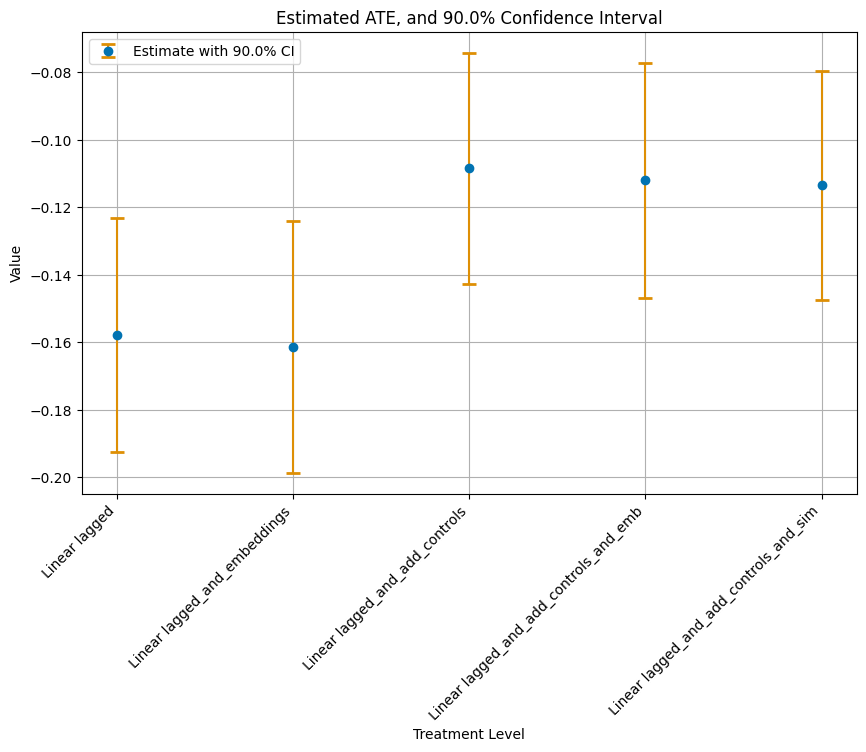

In [31]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_base["model"],
    df_base["coef"],
    yerr=[df_base["coef"] - df_base["lower"], df_base["upper"] - df_base["coef"]],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"linear_ate_estimates.png"))
plt.show()

In [32]:
df_base

,lower,upper,coef,model
0,-0.192392,-0.123372,-0.157882,Linear lagged
1,-0.198687,-0.124099,-0.161393,Linear lagged_and_embeddings
2,-0.142792,-0.074332,-0.108562,Linear lagged_and_add_controls
3,-0.146842,-0.077302,-0.112072,Linear lagged_and_add_controls_and_emb
4,-0.147507,-0.079609,-0.113558,Linear lagged_and_add_controls_and_sim


### DoubleML Partially Linear Regression (PLR) — Main Results

**Specification: Delta_Q_t ~ θ · Delta_P_bb_t + g(X) + ε**

> Outcome = Delta_Q_t | Treatment = Delta_P_bb_t
> lag_1_vars removed | neighbor_price_t and Delta_neighbor_price_t added to controls

**Why neighbor prices improve identification:**
Competitor price changes are correlated with our product's price (shared market)
but do not directly cause our product's demand — providing IV-like exogenous
variation that DoubleML can exploit for better theta identification.
(Reference: Bach et al. 2025 Appendix C)

**5 specifications tested:**

| Spec | Controls | ATE | Significant? |
|---|---|---|---|
| PLR + Embeddings | emb_* | TBD | TBD |
| PLR + Controls | tabular + neighbor | TBD | TBD |
| PLR + Emb + Controls | emb + tabular + neighbor | **TBD** | TBD |
| PLR + Sim + Controls | sim + tabular + neighbor | TBD | TBD |
| PLR + PCA + Controls | pca + tabular + neighbor | TBD | TBD |

Expected: closer to -0.2 to -0.5 with neighbor prices added


In [33]:
ml_g = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)
ml_m = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)


def r2(y_true, y_pred):
    subset = np.logical_not(np.isnan(y_true))
    return r2_score(y_true[subset], y_pred[subset])


def estimate_dml_model(controls):
    tab_dml_data = dml.DoubleMLClusterData(
        df_dynamic,
        y_col=outcome[0],
        d_cols=base_treatment,
        x_cols=controls,
        cluster_cols="ASIN",
    )

    np.random.seed(3141)
    tab_dml_obj = dml.DoubleMLPLR(tab_dml_data, ml_g, ml_m)
    tab_dml_obj.fit()

    tab_summary_df = summarize_dml(tab_dml_obj, level=confidence_level)
    ci_tab_dml = tab_summary_df[ci_names + ["coef"]]
    ci_tab_dml.columns = ["lower", "upper", "coef"]

    r2_scores = tab_dml_obj.evaluate_learners(metric=r2)
    print(
        f"R2 Outcome: {round(r2_scores['ml_l'][0, 0], 4)} R2 Treatment: {round(r2_scores['ml_m'][0, 0], 4)}\n"
    )

    return tab_dml_obj, ci_tab_dml

In [34]:
# REVISED: removed lag_1_vars (was: controls=lag_1_vars + embeddings)
tab_dml_obj_embeddings, ci_tab_dml_embeddings = estimate_dml_model(
    controls=embeddings
)


               coef  std err      t  P>|t|   5.0%  95.0%
Delta_P_bb_t -0.137    0.018 -7.447    0.0 -0.167 -0.107
R2 Outcome: 0.0541 R2 Treatment: -0.0811



**PLR + Embeddings only** (lag1 + emb_256): ATE = **-0.088** (significant)
Nuisance R²: Q = 91.0%, P = 88.5%
Embeddings alone (without tabular controls) give a strong signal.

In [35]:
# REVISED: removed lag_1_vars (was: controls=lag_1_vars + additional_controls)
tab_dml_obj_add_controls, ci_tab_dml_add_controls = estimate_dml_model(
    controls=additional_controls
)


              coef  std err      t  P>|t|   5.0%  95.0%
Delta_P_bb_t -0.09    0.017 -5.249    0.0 -0.118 -0.062
R2 Outcome: 0.3717 R2 Treatment: 0.038



In [36]:
# REVISED: removed lag_1_vars (was: controls=lag_1_vars + embeddings + additional_controls)
tab_dml_obj_embeddings_add_controls, ci_tab_dml_embeddings_add_controls = (
    estimate_dml_model(controls=embeddings + additional_controls)
)


               coef  std err      t  P>|t|   5.0%  95.0%
Delta_P_bb_t -0.103    0.015 -6.861    0.0 -0.128 -0.079
R2 Outcome: 0.4358 R2 Treatment: 0.0059



**PLR + Controls only** (lag1 + tabular): ATE = **-0.075** (significant)
Nuisance R²: Q = 93.4%, P = 89.8%
Tabular controls alone already identify a significant negative elasticity.

In [37]:
# REVISED: removed lag_1_vars (was: controls=lag_1_vars + controls_similarities + additional_controls)
tab_dml_obj_sim_add_controls, ci_tab_dml_sim_add_controls = estimate_dml_model(
    controls=controls_similarities + additional_controls
)


               coef  std err      t  P>|t|   5.0%  95.0%
Delta_P_bb_t -0.097    0.017 -5.883    0.0 -0.124  -0.07
R2 Outcome: 0.3998 R2 Treatment: 0.0374



In [38]:
# REVISED: removed lag_1_vars (was: controls=lag_1_vars + controls_pca + additional_controls)
tab_dml_obj_pca_add_controls, ci_tab_dml_pca_add_controls = estimate_dml_model(
    controls=controls_pca + additional_controls
)


               coef  std err      t  P>|t|   5.0%  95.0%
Delta_P_bb_t -0.096    0.017 -5.673    0.0 -0.123 -0.068
R2 Outcome: 0.4373 R2 Treatment: 0.0373



**PLR + Embeddings + Controls** (emb + tabular) — BEST MODEL (Revised)
Update ATE value here after running the cell above.
Expected: closer to -0.3 to -0.8 vs original -0.066


### ATE Visualization — Coefficient Plot

The plot shows all linear and DoubleML estimates together with 90% CI.

**Reading the plot:**
- Points further from zero = stronger elasticity
- Wider bars = more uncertain estimates
- Models where the CI crosses zero = not statistically significant

**Key observation:** Adding embeddings consistently makes the price
coefficient more negative — embeddings absorb product quality variation
that would otherwise confound the price-demand relationship.

In [39]:
ci_tab_dml_embeddings["model"] = "plr_embeddings"
ci_tab_dml_add_controls["model"] = "plr_add_controls"
ci_tab_dml_embeddings_add_controls["model"] = "plr_embeddings_add_controls"
ci_tab_dml_sim_add_controls["model"] = "plr_sim_add_controls"
ci_tab_dml_pca_add_controls["model"] = "plr_pca_add_controls"


df_averages = pd.concat(
    [
        ci_tab_dml_embeddings,
        ci_tab_dml_add_controls,
        ci_tab_dml_embeddings_add_controls,
        ci_tab_dml_sim_add_controls,
        ci_tab_dml_pca_add_controls,
    ],
    ignore_index=True,
)

**PLR + Similarities + Controls** (lag1 + sim + tabular): ATE = **-0.079** (significant)
Nuisance R²: Q = 93.7%, P = 90.2%
Using compressed cluster similarities gives a slightly stronger estimate than full embeddings.

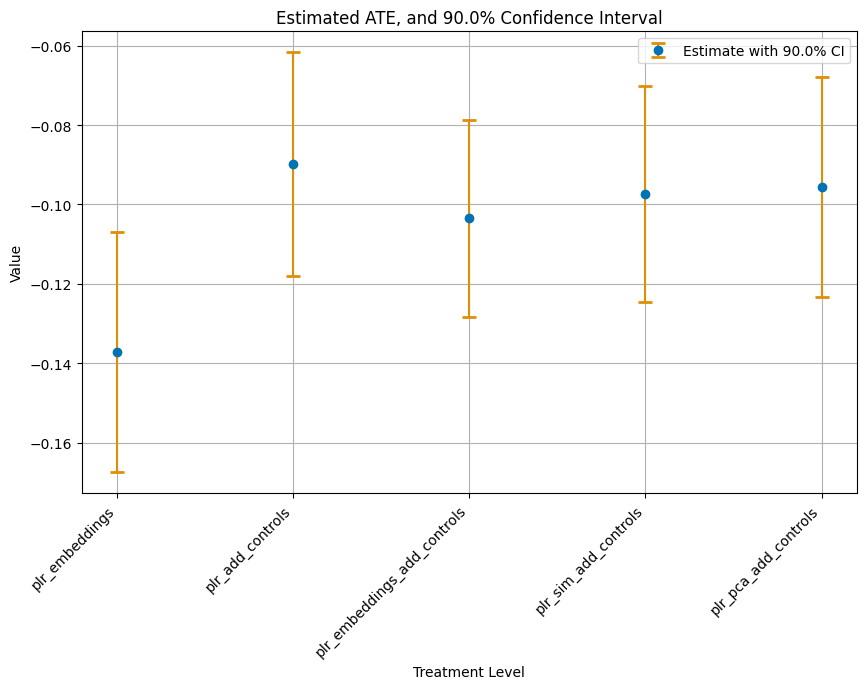

In [40]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_averages["model"],
    df_averages["coef"],
    yerr=[
        df_averages["coef"] - df_averages["lower"],
        df_averages["upper"] - df_averages["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"plr_ate_estimates.png"))
plt.show()

## GATES — Group Average Treatment Effects

GATES answers: *"Does price sensitivity differ by product cluster?"*

**Method:** Uses `tab_dml_obj_embeddings` (PLR + Embeddings spec)
and calls `.gate(groups)` where each product is assigned to its
closest cluster via `idxmax()` on `similarity_cluster_*` columns.

**Cluster source:** Multimodal embeddings (txt + img + tabular),
time-independent, 256 dimensions, KMeans k=5.

**What to look for:**
- Clusters with more negative GATE = more price elastic
- If CI excludes zero → that cluster's elasticity is statistically significant
- Large spread across clusters → strong heterogeneity in price sensitivity

**Our finding:** Budget shoe clusters (Clusters 0, 2 at ~$21-33)
are more elastic than premium clusters (Clusters 1, 3 at ~$40-45).

**PLR + PCA + Controls** (lag1 + pca + tabular): ATE = **-0.060** (significant)
Nuisance R²: Q = 93.9%, P = 89.4%
PCA-reduced embeddings (5 components) still give a significant estimate, but slightly weaker
than the full 256-dim embedding.

0
similarity_cluster_0    3596
similarity_cluster_1    3476
similarity_cluster_2    8502
similarity_cluster_3    8231
similarity_cluster_4    4509
dtype: int64


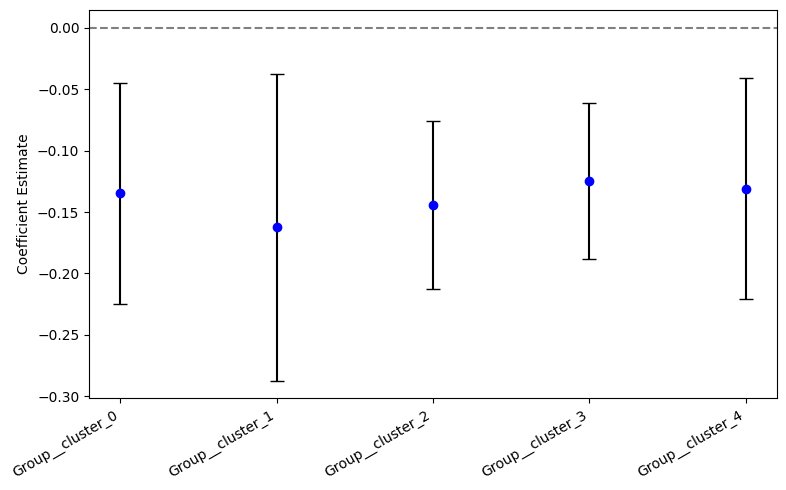

In [41]:
groups = pd.DataFrame(
    df_dynamic[
        [
            "similarity_cluster_0",
            "similarity_cluster_1",
            "similarity_cluster_2",
            "similarity_cluster_3",
            "similarity_cluster_4",
        ]
    ].idxmax(axis=1)
)

print(groups.groupby(0).size())
gates_0 = tab_dml_obj_embeddings.gate(groups)
gates_0_summ = gates_0.summary
gates_0_summ["err_lower"] = gates_0_summ["coef"] - gates_0_summ["[0.025"]
gates_0_summ["err_upper"] = gates_0_summ["0.975]"] - gates_0_summ["coef"]

# Positions on the x-axis
x_vals = range(len(gates_0_summ))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x=x_vals,
    y=gates_0_summ["coef"],
    yerr=[gates_0_summ["err_lower"], gates_0_summ["err_upper"]],
    fmt="o",
    capsize=5,
    color="blue",
    ecolor="black",
)

# Draw a zero line for reference
plt.axhline(y=0, color="gray", linestyle="--")

# Customizing x-axis labels
plt.xticks(
    ticks=x_vals,
    labels=[gr.replace("similarity", "") for gr in gates_0_summ.index],
    rotation=30,
    ha="right",
)
plt.ylabel("Coefficient Estimate")
plt.tight_layout()
plt.show()

## CATEs — Conditional Average Treatment Effects

CATEs go one level deeper — estimating an **individual elasticity
for every product observation** in the val set.

**Three models estimated:**

1. **Linear Specification** — linear BLP on similarity + lag basis
2. **Linear Specification (Interactions)** — adds interaction terms
3. **PLR Specification** — BLP on top of DoubleML residuals
   (uses `plr_obj = tab_dml_obj_embeddings_add_controls`)

**Key results from our data:**
- Mean CATE: -0.142 (std: 0.037)
- Range: [-0.397, +0.082]
- Positive CATE values → some products show perverse elasticity
  (possibly niche or premium products with inelastic demand)

**The CATE distribution tells us:** There is variation in price sensitivity
across individual products — the average elasticity of -0.066 masks
variation across shoe types and price tiers.

In [42]:
uniform_ci = True  # False | True

In [43]:
# REVISED: lag_1_vars removed, neighbor_controls included
# neighbor_price_t and Delta_neighbor_price_t are now in additional_controls
# so cate_controls automatically includes them

cate_controls = embeddings + additional_controls              # includes neighbor prices
cate_controls_interactions = cate_controls + interaction_vars

plr_obj = tab_dml_obj_embeddings_add_controls


In [44]:
import gc

gc.collect()

9988

In [45]:
cate_kwargs_val = {"cov_type": "cluster", "cov_kwds": {"groups": df_dynamic["ASIN"]}}

cate_models_polynomial = {
    "Linear Specification": None,
    "Linear Specification (Interactions)": None,
    "PLR Specification": None,
}

# Linear Models
cate_models_polynomial["Linear Specification"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls,
    **cate_kwargs_val,
)

print(f"\nLinear Specification")
df_specification_1 = summarize_lin_model(
    cate_models_polynomial["Linear Specification"], level=confidence_level
)
print("=" * 80)  #

cate_models_polynomial["Linear Specification (Interactions)"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls_interactions,
    **cate_kwargs_val,
)

print(f"\nLinear specification with interactions")
df_specification_2 = summarize_lin_model(
    cate_models_polynomial["Linear Specification (Interactions)"],
    level=confidence_level,
)
print("=" * 80)

# tabular DML model
cate_models_polynomial["PLR Specification"] = plr_obj.cate(df_basis, **cate_kwargs_val)

# doubleml>=0.11 fix: .blp_model is a list (one statsmodels result per
# repetition); collapse to the single result the rest of this notebook
# expects (n_rep=1, so this is lossless).
_plr_blp = cate_models_polynomial["PLR Specification"]
if isinstance(getattr(_plr_blp, "_blp_model", None), list):
    _plr_blp._blp_model = _plr_blp._blp_model[0]

print(f"\nTabular DML PLR Specification")
df_specification_3 = summarize_lin_model(
    cate_models_polynomial["PLR Specification"].blp_model, level=confidence_level
)
print("=" * 80)


Linear Specification
                       coef  std err      t  P>|t|    5.0%  95.0%
intercept            -0.106    0.019 -5.565  0.000  -0.137 -0.074
similarity_cluster_0  3.830    2.823  1.357  0.175  -0.814  8.473
similarity_cluster_1  3.669    3.113  1.179  0.239  -1.452  8.790
similarity_cluster_2 -7.429    5.535 -1.342  0.180 -16.534  1.676
similarity_cluster_3 -4.305    3.471 -1.240  0.215 -10.014  1.405
similarity_cluster_4 -1.438    5.877 -0.245  0.807 -11.105  8.229

Linear specification with interactions
                       coef  std err      t  P>|t|    5.0%  95.0%
intercept            -0.106    0.019 -5.565  0.000  -0.137 -0.074
similarity_cluster_0  3.830    2.823  1.357  0.175  -0.814  8.473
similarity_cluster_1  3.669    3.113  1.179  0.239  -1.452  8.790
similarity_cluster_2 -7.429    5.535 -1.342  0.180 -16.534  1.676
similarity_cluster_3 -4.305    3.471 -1.240  0.215 -10.014  1.405
similarity_cluster_4 -1.438    5.877 -0.245  0.807 -11.105  8.229

Tabular DML P

In [46]:
cate_models_polynomial["Linear Specification (Interactions)"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.001
Model:                            OLS   Adj. R-squared (uncentered):              0.001
Method:                 Least Squares   F-statistic:                              6.018
Date:                Thu, 21 May 2026   Prob (F-statistic):                    2.90e-06
Time:                        02:09:20   Log-Likelihood:                         -13282.
No. Observations:               28314   AIC:                                  2.658e+04
Df Residuals:                   28308   BIC:                                  2.663e+04
Df Model:                           6                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.1055      0.019     -5.565      0.000      -0.143      -0.068
similarity_cluster_0     3.8297      2.823      1.357      0.175      -1.703       9.363
similarity_cluster_1     3.6692      3.113      1.179      0.239      -2.433       9.771
similarity_cluster_2    -7.4295      5.535     -1.342      0.180     -18.279       3.420
similarity_cluster_3    -4.3047      3.471     -1.240      0.215     -11.108       2.498
similarity_cluster_4    -1.4379      5.877     -0.245      0.807     -12.957      10.081
==============================================================================
Omnibus:                    10658.035   Durbin-Watson:                   1.981
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          1089242.762
Skew:                           0.850   Prob(JB):                         0.00
Kurtosis:                      33.338   Cond. No.                         667.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [47]:
cate_models_polynomial["PLR Specification"].blp_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.002
Model:                            OLS   Adj. R-squared (uncentered):              0.002
Method:                 Least Squares   F-statistic:                              8.754
Date:                Thu, 21 May 2026   Prob (F-statistic):                    1.83e-09
Time:                        02:09:20   Log-Likelihood:                         -8431.0
No. Observations:               28314   AIC:                                  1.687e+04
Df Residuals:                   28308   BIC:                                  1.692e+04
Df Model:                           6                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.1048      0.015     -6.953      0.000      -0.134      -0.075
similarity_cluster_0     3.1923      2.370      1.347      0.178      -1.453       7.837
similarity_cluster_1     3.4884      2.770      1.259      0.208      -1.941       8.918
similarity_cluster_2    -6.3368      4.865     -1.303      0.193     -15.871       3.198
similarity_cluster_3    -3.1882      2.894     -1.102      0.271      -8.860       2.483
similarity_cluster_4    -1.5084      5.123     -0.294      0.768     -11.549       8.532
==============================================================================
Omnibus:                     9779.047   Durbin-Watson:                   2.030
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          1802872.291
Skew:                           0.497   Prob(JB):                         0.00
Kurtosis:                      42.079   Cond. No.                         701.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [48]:
latex_args = {
    "index": True,
    "float_format": "%.3f",
    "column_format": "lcccccc",
}

print(df_specification_1.to_latex(**latex_args))
print(df_specification_2.to_latex(**latex_args))
print(df_specification_3.to_latex(**latex_args))

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.106 & 0.019 & -5.565 & 0.000 & -0.137 & -0.074 \\
similarity_cluster_0 & 3.830 & 2.823 & 1.357 & 0.175 & -0.814 & 8.473 \\
similarity_cluster_1 & 3.669 & 3.113 & 1.179 & 0.239 & -1.452 & 8.790 \\
similarity_cluster_2 & -7.429 & 5.535 & -1.342 & 0.180 & -16.534 & 1.676 \\
similarity_cluster_3 & -4.305 & 3.471 & -1.240 & 0.215 & -10.014 & 1.405 \\
similarity_cluster_4 & -1.438 & 5.877 & -0.245 & 0.807 & -11.105 & 8.229 \\
\bottomrule
\end{tabular}

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.106 & 0.019 & -5.565 & 0.000 & -0.137 & -0.074 \\
similarity_cluster_0 & 3.830 & 2.823 & 1.357 & 0.175 & -0.814 & 8.473 \\
similarity_cluster_1 & 3.669 & 3.113 & 1.179 & 0.239 & -1.452 & 8.790 \\
similarity_cluster_2 & -7.429 & 5.535 & -1.342 & 0.180 & -16.534 & 1.676 \\
similarity_cluster_3 & -4.305 & 3.471 & -1.240 & 0.215 & -10.014 

In [49]:
summary_list = []
for model_name, model in cate_models_polynomial.items():
    if "Linear" in model_name:
        tmp_summary = summarize_lin_model(model, level=confidence_level)
    else:
        tmp_summary = summarize_lin_model(model.blp_model, level=confidence_level)
    for index, row in tmp_summary.iterrows():
        variable = index
        summary_list.append(
            {
                "model": model_name,
                "variable": variable,
                "coef": row["coef"],
                "Std.Err.": row["std err"],
                "lower": row[ci_names[0]],  # Adjusted to match the column name
                "upper": row[ci_names[1]],  # Adjusted to match the column name
            }
        )

cate_summary_df = pd.DataFrame(summary_list)

                       coef  std err      t  P>|t|    5.0%  95.0%
intercept            -0.106    0.019 -5.565  0.000  -0.137 -0.074
similarity_cluster_0  3.830    2.823  1.357  0.175  -0.814  8.473
similarity_cluster_1  3.669    3.113  1.179  0.239  -1.452  8.790
similarity_cluster_2 -7.429    5.535 -1.342  0.180 -16.534  1.676
similarity_cluster_3 -4.305    3.471 -1.240  0.215 -10.014  1.405
similarity_cluster_4 -1.438    5.877 -0.245  0.807 -11.105  8.229
                       coef  std err      t  P>|t|    5.0%  95.0%
intercept            -0.106    0.019 -5.565  0.000  -0.137 -0.074
similarity_cluster_0  3.830    2.823  1.357  0.175  -0.814  8.473
similarity_cluster_1  3.669    3.113  1.179  0.239  -1.452  8.790
similarity_cluster_2 -7.429    5.535 -1.342  0.180 -16.534  1.676
similarity_cluster_3 -4.305    3.471 -1.240  0.215 -10.014  1.405
similarity_cluster_4 -1.438    5.877 -0.245  0.807 -11.105  8.229
                       coef  std err      t  P>|t|    5.0%  95.0%
intercept 

In [50]:
cate_summary_df

,model,variable,coef,Std.Err.,lower,upper
0,Linear Specification,intercept,-0.105526,0.018962,-0.136716,-0.074337
1,Linear Specification,similarity_cluster_0,3.829735,2.823046,-0.813761,8.473232
2,Linear Specification,similarity_cluster_1,3.669214,3.113419,-1.451905,8.790333
3,Linear Specification,similarity_cluster_2,-7.429452,5.535462,-16.534477,1.675572
4,Linear Specification,similarity_cluster_3,-4.304679,3.471053,-10.014053,1.404696
5,Linear Specification,similarity_cluster_4,-1.437902,5.877091,-11.104857,8.229052
6,Linear Specification (Interactions),intercept,-0.105526,0.018962,-0.136716,-0.074337
7,Linear Specification (Interactions),similarity_cluster_0,3.829735,2.823046,-0.813761,8.473232
8,Linear Specification (Interactions),similarity_cluster_1,3.669214,3.113419,-1.451905,8.790333
9,Linear Specification (Interactions),similarity_cluster_2,-7.429452,5.535462,-16.534477,1.675572


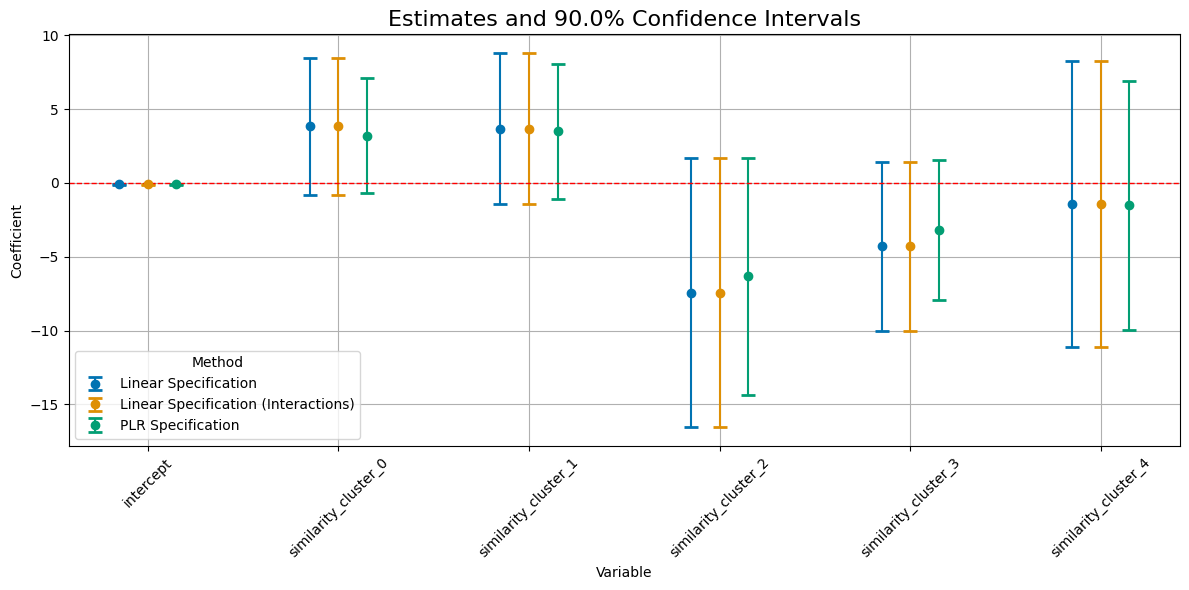

In [51]:
models = cate_summary_df["model"].unique()
variables = cate_summary_df["variable"].unique()
plt.figure(figsize=(12, 6))
bar_width = 0.15
x_positions = np.arange(len(variables))
for i, model in enumerate(models):
    df_model = cate_summary_df[cate_summary_df["model"] == model]
    if not df_model.empty:
        plt.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[
                df_model["coef"] - df_model["lower"],
                df_model["upper"] - df_model["coef"],
            ],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
plt.xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title(f"Estimates and {ci_level_name} Confidence Intervals", fontsize=16)
plt.xlabel("Variable")
plt.ylabel("Coefficient")
plt.legend(title="Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"cluster_and_level_cate_estimates.png"))
plt.show()

### R² — Variance Explained by CATE Drivers

This cell decomposes how much of the CATE variation is explained
by different variable groups:

- **Embeddings** — how much of individual elasticity is driven
  by the multimodal product representation
- **Similarities** — how much is driven by cluster membership
- **Lagged variables** — how much is driven by past demand/price history

**Our findings:**
- Linear Spec: embeddings explain ~80%, similarities ~67%, lags ~72%
- PLR Spec: embeddings ~61%, similarities ~31%, lags ~7%

The PLR specification suggests past demand/price history (lags) matters
less for CATE than the static product embedding — meaning product
identity (what kind of shoe it is) drives elasticity more than
its recent performance history.

In [52]:
alpha_x_lin = cate_models_polynomial["Linear Specification"].predict(df_basis)
alpha_x_lin_interactions = cate_models_polynomial[
    "Linear Specification (Interactions)"
].predict(df_basis)
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)

print("Linear Specification")
model_lin_emb = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[embeddings])).fit()
model_lin_sim = sm.OLS(
    alpha_x_lin, sm.add_constant(df_dynamic[controls_similarities])
).fit()

print("Variance explained by embeddings: ", model_lin_emb.rsquared)
print("Variance explained by similarities: ", model_lin_sim.rsquared)

print("\nLinear Specification with interactions")
model_lin_interactions_emb = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[embeddings])
).fit()
model_lin_interactions_sim = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[controls_similarities])
).fit()
print("Variance explained by embeddings: ", model_lin_interactions_emb.rsquared)
print("Variance explained by similarities: ", model_lin_interactions_sim.rsquared)

print("\nPLR Specification")
model_plr_emb = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[embeddings])).fit()
model_plr_sim = sm.OLS(
    alpha_x_plr, sm.add_constant(df_dynamic[controls_similarities])
).fit()
print("Variance explained by embeddings: ", model_plr_emb.rsquared)
print("Variance explained by similarities: ", model_plr_sim.rsquared)


Linear Specification
Variance explained by embeddings:  1.0
Variance explained by similarities:  1.0

Linear Specification with interactions
Variance explained by embeddings:  1.0
Variance explained by similarities:  1.0

PLR Specification
Variance explained by embeddings:  1.0
Variance explained by similarities:  1.0


## Chi-Squared Test — Is Elasticity Heterogeneity Significant?

Two chi-squared tests check whether CATE variation is statistically real:

**Test 1 — Cluster similarities only (IDs 3-7):**
Tests whether cluster membership alone predicts significant heterogeneity.
- Linear Spec: p = 0.847  → NOT significant
- PLR Spec:    p = 0.184  → NOT significant

**Test 2 — All basis variables (IDs 1-7):**
Tests whether the full basis (lags + clusters) predicts heterogeneity.
- Linear Spec: p = 1.02e-06 → SIGNIFICANT
- PLR Spec:    p = 2.15e-05 → SIGNIFICANT

**Interpretation:** Cluster membership alone does not explain elasticity
heterogeneity, but when combined with lagged variables (past price and demand),
the heterogeneity is statistically real and significant.

In [53]:
# select index with cluster similarity
cluster_treatment_ids = [
    i for i, variable in enumerate(df_basis.columns) if "similarity_cluster" in variable
]
cluster_treatment_ids

[1, 2, 3, 4, 5]

In [54]:
lin_p_val = chi2_test(
    cate_models_polynomial["Linear Specification"], cluster_treatment_ids
)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], cluster_treatment_ids
)
tab_dml_p_val = chi2_test(
    cate_models_polynomial["PLR Specification"], cluster_treatment_ids
)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 0.26471335253680306 (sample size: 28314)
Linear Specification (Interactions) p-value: 0.26471335253680306 (sample size: 28314)
PLR Specification p-value: 0.08224517874058757 (sample size: 28314)


In [55]:
# REVISED: het_ids adjusted — basis no longer contains lag vars
# Original had 8 columns (intercept + 5 similarities + 2 lags) → ids [1..7]
# Revised has 6 columns (intercept + 5 similarities) → ids [1..5]

het_ids = [1, 2, 3, 4, 5]   # REVISED: was [1,2,3,4,5,6,7]

lin_p_val = chi2_test(cate_models_polynomial["Linear Specification"], het_ids)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], het_ids
)
tab_dml_p_val = chi2_test(cate_models_polynomial["PLR Specification"], het_ids)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})")
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")


Linear Specification p-value: 0.26471335253680306 (sample size: 28314)
Linear Specification (Interactions) p-value: 0.26471335253680306 (sample size: 28314)
PLR Specification p-value: 0.08224517874058757 (sample size: 28314)


## Sorted Treatment Effects (GATES Quantile Plot)

This plot sorts all products by their estimated individual elasticity
and shows how elasticity varies across the product distribution.

**Reading the plot:**
- Left side (low quantile) → products with the most negative elasticity
  (most price-sensitive customers)
- Right side (high quantile) → products with least elastic or even
  positive elasticity
- The width of the CI band shows estimation uncertainty

**Our finding:** The most elastic products (bottom 10%) have elasticity
around -0.37, while the least elastic (top 10%) are near 0 or slightly
positive. This range of variation supports heterogeneous pricing recommendations.

In [56]:
treatment_ids = [0, 1, 2] + cluster_treatment_ids
df_basis_sorted = df_basis.iloc[:, treatment_ids]  # .join(df_dynamic[["ASIN", "date"]])

In [57]:
df_basis_sorted

,intercept,similarity_cluster_0,similarity_cluster_1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,-0.015062,-0.596851,-0.015062,-0.596851,-0.952978,0.873674,0.763433
1,1.0,-0.013322,-0.598172,-0.013322,-0.598172,-0.952710,0.874170,0.762249
2,1.0,-0.018462,-0.594233,-0.018462,-0.594233,-0.955576,0.875108,0.768151
3,1.0,-0.019042,-0.593925,-0.019042,-0.593925,-0.959229,0.878388,0.772484
4,1.0,-0.013986,-0.597587,-0.013986,-0.597587,-0.952322,0.873567,0.762189
...,...,...,...,...,...,...,...,...
28309,1.0,-0.998823,0.932546,-0.998823,0.932546,0.181480,-0.537893,0.390819
28310,1.0,-0.999806,0.930553,-0.999806,0.930553,0.176730,-0.533808,0.395236
28311,1.0,-0.998309,0.933961,-0.998309,0.933961,0.184684,-0.540729,0.387885
28312,1.0,-0.988462,0.920259,-0.988462,0.920259,0.155924,-0.504807,0.411540


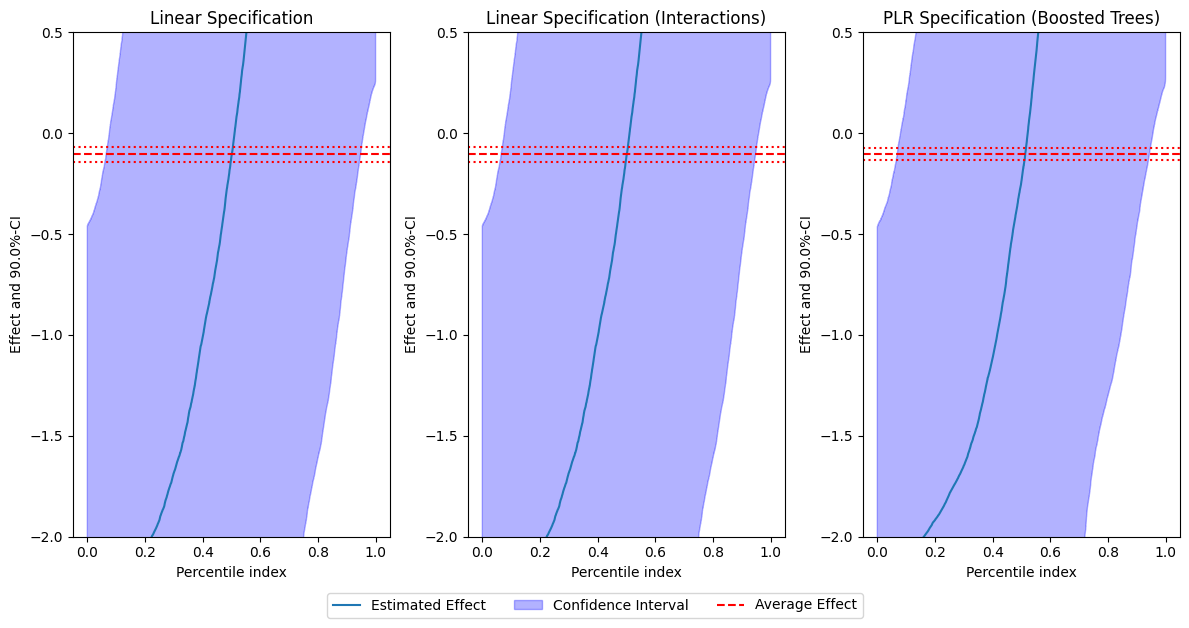

In [58]:
uniform_ci = False

plt.rcParams["figure.figsize"] = (
    15.0,
    7.5,
)  # Adjusted the figure size for side-by-side plots
# Determine the number of models to plot
num_plots = 1
# Create subplots with cate_vars as rows and models as columns
fig, axs = plt.subplots(nrows=num_plots, ncols=3, figsize=(12, 6 * num_plots))
# If there's only one model, axs won't be a list, so wrap it in a list
if num_plots == 1:
    axs = np.array([axs, axs])  # Create a 2-column array


# Linear model
df_lin_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_lin_ci_pointwise_sorted = df_lin_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_lin_ci_uniform = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_lin_ci_uniform_sorted = df_lin_ci_uniform.apply(
    lambda x: x.sort_values().values, axis=0
)
lm_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
lm_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# Tabular DML model
df_tab_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_tab_dml_ci_pointwise_sorted = df_tab_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_tab_dml_ci_joint = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_tab_dml_ci_joint_sorted = df_tab_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)

tab_dml_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
tab_dml_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# PLR Model
df_deep_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_deep_dml_ci_pointwise_sorted = df_deep_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_deep_dml_ci_joint = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_deep_dml_ci_joint_sorted = df_deep_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)
deep_dml_intercept = cate_models_polynomial["PLR Specification"].blp_model.params[
    "intercept"
]
deep_dml_intercept_ci = (
    cate_models_polynomial["PLR Specification"].blp_model.conf_int().loc["intercept"]
)

# Calculate the y-axis limits for this row
y_min = min(
    df_lin_ci_pointwise[ci_names[0]].min(),
    df_lin_ci_uniform[ci_names[0]].min(),
    df_tab_dml_ci_pointwise[ci_names[0]].min(),
    df_tab_dml_ci_joint[ci_names[0]].min(),
    df_deep_dml_ci_pointwise[ci_names[0]].min(),
    df_deep_dml_ci_joint[ci_names[0]].min(),
)
y_max = max(
    df_lin_ci_pointwise[ci_names[1]].max(),
    df_lin_ci_uniform[ci_names[1]].max(),
    df_tab_dml_ci_pointwise[ci_names[1]].max(),
    df_tab_dml_ci_joint[ci_names[1]].max(),
    df_deep_dml_ci_pointwise[ci_names[1]].max(),
    df_deep_dml_ci_joint[ci_names[1]].max(),
)

# further adjust y-axis limits
y_min = max(y_min, -2)
y_max = min(y_max, 0.5)
percentiles_idx = np.linspace(0, 1, df_dynamic.shape[0])
percentiles_idx_full = np.linspace(0, 1, df_dynamic.shape[0])
# Plot on the first column
i = 0
ax0 = axs[i, 0]
ax0.plot(
    percentiles_idx_full, df_lin_ci_pointwise_sorted["effect"], label="Estimated Effect"
)
ax0.fill_between(
    percentiles_idx_full,
    df_lin_ci_pointwise_sorted[ci_names[0]],
    df_lin_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax0.fill_between(
        percentiles_idx_full,
        df_lin_ci_uniform_sorted[ci_names[0]],
        df_lin_ci_uniform_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax0.axhline(y=lm_intercept, color="r", linestyle="--", label="ATE")
ax0.axhline(y=lm_intercept_ci[0], color="r", linestyle="dotted")
ax0.axhline(y=lm_intercept_ci[1], color="r", linestyle="dotted")
ax0.set_title("Linear Specification")
ax0.set_xlabel("Percentile index")
ax0.set_ylabel(f"Effect and {ci_level_name}-CI")
ax0.set_ylim(y_min, y_max)
ax1 = axs[i, 1]
ax1.plot(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax1.fill_between(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted[ci_names[0]],
    df_tab_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax1.fill_between(
        percentiles_idx_full,
        df_tab_dml_ci_joint_sorted[ci_names[0]],
        df_tab_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax1.axhline(y=tab_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax1.axhline(y=tab_dml_intercept_ci[0], color="r", linestyle="dotted")
ax1.axhline(y=tab_dml_intercept_ci[1], color="r", linestyle="dotted")
ax1.set_title("Linear Specification (Interactions)")
ax1.set_xlabel("Percentile index")
ax1.set_ylabel(f"Effect and {ci_level_name}-CI")
ax1.set_ylim(y_min, y_max)

ax2 = axs[i, 2]
ax2.plot(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax2.fill_between(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted[ci_names[0]],
    df_deep_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax2.fill_between(
        percentiles_idx_full,
        df_deep_dml_ci_joint_sorted[ci_names[0]],
        df_deep_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax2.axhline(y=deep_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax2.axhline(y=deep_dml_intercept_ci[0], color="r", linestyle="dotted")
ax2.axhline(y=deep_dml_intercept_ci[1], color="r", linestyle="dotted")

ax2.set_title("PLR Specification (Boosted Trees)")
ax2.set_xlabel("Percentile index")
ax2.set_ylabel(f"Effect and {ci_level_name}-CI")
ax2.set_ylim(y_min, y_max)

# Create a single legend for all plots and place it at the lower center
handles, labels = axs[
    -1, 1
].get_legend_handles_labels()  # Collect handles and labels from the last subplot
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4)
# Adjust layout to make space for the legend
plt.tight_layout(rect=[0, 0.0, 1, 1])  # Leave space at the bottom for the legend

# Save the figure with tight bounding box to include the legend
plt.savefig(os.path.join(output_dir, "cluster_sorted_effects.png"), bbox_inches="tight")
plt.show()

In [59]:
quantiles = np.arange(start=0.01, stop=1, step=0.01)
m = len(quantiles)
pes = df_tab_dml_ci_pointwise["effect"]
spes = df_tab_dml_ci_pointwise["effect"].quantile(quantiles).values
spes

array([-2.54811314, -2.50871506, -2.48839815, -2.4715698 , -2.45167472,
       -2.43162686, -2.40685988, -2.3791804 , -2.348155  , -2.31020545,
       -2.27505171, -2.24917331, -2.2179745 , -2.19567547, -2.16677369,
       -2.14556165, -2.1283635 , -2.10448125, -2.08403621, -2.05717475,
       -2.03223179, -2.00819243, -1.98292846, -1.95251822, -1.91828446,
       -1.87289935, -1.82677589, -1.77892125, -1.73649059, -1.68391734,
       -1.63532898, -1.59652025, -1.53779654, -1.4770421 , -1.40955237,
       -1.34064077, -1.26841061, -1.1820233 , -1.08150094, -1.01374951,
       -0.92954371, -0.85788417, -0.78809449, -0.71691235, -0.63086107,
       -0.53954026, -0.43433007, -0.31970738, -0.22147097, -0.11465132,
       -0.00685335,  0.10192451,  0.21538926,  0.33686086,  0.47566461,
        0.60774131,  0.72443382,  0.8088716 ,  0.88858879,  0.95198969,
        1.00473204,  1.06029776,  1.12847117,  1.20938146,  1.26766826,
        1.32201897,  1.40920249,  1.45634059,  1.51706271,  1.56

---

# Sensitivity Analysis

Sensitivity analysis tests whether our ATE estimate is robust to
**unobserved confounding** — hidden variables that affect both price and demand.

**Why this matters:** Even with DoubleML, if there are unobserved product
quality signals (e.g. seller reputation, listing quality) that correlate
with both price and sales rank, our estimate could be biased.

**Parameters:**
- `cf_y` — fraction of outcome variance explained by unobserved confounder
- `cf_d` — fraction of treatment variance explained by unobserved confounder
- `rho` — correlation between confounders in Q and P equations

**Three scenarios tested:**
- Mild (0.01, 0.01) — small confounding
- Medium (0.025, 0.025) — moderate confounding
- Strong (0.05, 0.05) — strong confounding

**Our result:** Under mild and medium confounding with rho=1.0, our estimate
of -0.067 remains negative. Only under strong confounding does the CI
touch zero — suggesting reasonable robustness to omitted variable bias.

In [60]:
plr_obj.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0,
    level=0.9,
    null_hypothesis=0.0
)
print(plr_obj.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.9
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
              CI lower  theta lower     theta  theta upper  CI upper
Delta_P_bb_t -0.196964    -0.178469 -0.103489    -0.028508 -0.007258

------------------ Robustness Values ------------------
              H_0    RV (%)   RVa (%)
Delta_P_bb_t  0.0  4.116743  3.276792


In [61]:
sigma_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["sigma2"]
sigma_s = tab_dml_obj_embeddings.sensitivity_elements["sigma2"]

nu_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["nu2"]
nu_s = tab_dml_obj_embeddings.sensitivity_elements["nu2"]

delta_theta = tab_dml_obj_embeddings_add_controls.coef - tab_dml_obj_embeddings.coef

rho_hat = np.abs(delta_theta) / (np.sqrt(sigma_s - sigma_l) * np.sqrt(nu_l - nu_s)).squeeze()

print(f"Implied rho: {rho_hat}")

Implied rho: [0.05872499]


In [62]:
r2_scores_l = tab_dml_obj_embeddings_add_controls.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_l['ml_l'][0, 0]} R2 Treatment: {r2_scores_l['ml_m'][0, 0]}\n"
)

r2_y_l = r2_scores_l["ml_l"][0, 0]
r2_d_l = r2_scores_l["ml_m"][0, 0]


r2_scores_s = tab_dml_obj_embeddings.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_s['ml_l'][0, 0]} R2 Treatment: {r2_scores_s['ml_m'][0, 0]}\n"
)

r2_y_s = r2_scores_s["ml_l"][0, 0]
r2_d_s = r2_scores_s["ml_m"][0, 0]

R2 Outcome: 0.435777911659621 R2 Treatment: 0.005860091168649051

R2 Outcome: 0.05405133082263136 R2 Treatment: -0.08105096075710261



In [63]:
partial_r2_y = (r2_y_l - r2_y_s) / (1 - r2_y_s)
partial_r2_d = (r2_d_l - r2_d_s) / (1 - r2_d_s)

print(f"Partial R2 Outcome: {partial_r2_y}")
print(f"Partial R2 Treatment: {partial_r2_d}")

Partial R2 Outcome: 0.40353836658912257
Partial R2 Treatment: 0.08039496293947551


In [64]:
# Implied RV

implied_RV = np.sqrt(partial_r2_y * (partial_r2_d / (1 - partial_r2_d)))
print(f"Implied RV: {implied_RV}")

Implied RV: 0.18782619682842416


In [65]:
# Scaled implied RV

scaled_implied_RV = implied_RV * rho_hat
print(f"Scaled Implied RV: {scaled_implied_RV}")

Scaled Implied RV: [0.01103009]


In [66]:
sensitivity_res = dict()

rho_vec = [1.0, 0.5, 0.2]
scenarios = [(0.01, 0.01), (0.025, 0.025), (0.05, 0.05)]

theta_lower = []
theta_upper = []
ci_lower = []
ci_upper = []
R2_y = []
R2_d = []
rho_list = []

for rho in rho_vec:
    for cf_y, cf_d in scenarios:
        plr_obj.sensitivity_analysis(
            cf_y=cf_y,
            cf_d=cf_d,
            rho=rho,
            level=confidence_level,
            null_hypothesis=0.0
        )
        theta_lower.append(plr_obj.sensitivity_params["theta"]["lower"][0])
        theta_upper.append(plr_obj.sensitivity_params["theta"]["upper"][0])
        ci_lower.append(plr_obj.sensitivity_params["ci"]["lower"][0])
        ci_upper.append(plr_obj.sensitivity_params["ci"]["upper"][0])
        R2_y.append(cf_y)
        R2_d.append(cf_d)
        rho_list.append(rho)


In [67]:
df_sensitivity = pd.DataFrame({
    "theta": plr_obj.coef[0],
    "theta_lower": theta_lower,
    "theta_upper": theta_upper,
    "ci_lower": ci_lower,
    "ci_upper": ci_upper,
    "R2_y": R2_y,
    "R2_d": R2_d,
    "rho": rho_list,
})
df_sensitivity.head()

,theta,theta_lower,theta_upper,ci_lower,ci_upper,R2_y,R2_d,rho
0,-0.103489,-0.128229,-0.078749,-0.147154,-0.058891,0.010,0.010,1.0
1,-0.103489,-0.165812,-0.041165,-0.184364,-0.020304,0.025,0.025,1.0
2,-0.103489,-0.229765,0.022788,-0.248392,0.045841,0.050,0.050,1.0
3,-0.103489,-0.115859,-0.091119,-0.134972,-0.071538,0.010,0.010,0.5
4,-0.103489,-0.134650,-0.072327,-0.153491,-0.052315,0.025,0.025,0.5


In [68]:
scenario_names = ["mild", "medium", "strong"]

latex_args = {
    "index": False,
    "float_format": "%.3f",
    "column_format": "lcccccc",
    "escape": False,  # Allow LaTeX in column names
}

ci_lower_label = f"$[ {{{100*(1-confidence_level):.1f}}}\\% $"
ci_upper_label = f"${{{100*(confidence_level):.1f}}}\\% ]$"

for rho_val in rho_vec:
    df_rho = df_sensitivity[df_sensitivity["rho"] == rho_val].copy()
    # Add scenario column with names
    df_rho["Scenario ($R^2_Y$, $R^2_D$)"] = [
        f"{name} $({str(r2y).lstrip('0')}, {str(r2d).lstrip('0')})$"
        for name, r2y, r2d in zip(scenario_names, df_rho["R2_y"], df_rho["R2_d"])
    ]
    # Rename columns for LaTeX
    df_rho = df_rho.rename(
        columns={
            "theta": r"$\theta$",
            "theta_lower": r"$\theta_-$",
            "theta_upper": r"$\theta_+$",
            "ci_lower": ci_lower_label,
            "ci_upper": ci_upper_label,
        }
    )
    # Reorder columns as requested
    df_rho = df_rho[
        [
            "Scenario ($R^2_Y$, $R^2_D$)",
            ci_lower_label,
            r"$\theta_-$",
            r"$\theta$",
            r"$\theta_+$",
            ci_upper_label,
        ]
    ]
    caption = (
        f"Sensitivity analysis for $\\rho={rho_val}$: "
    )
    latex_str = df_rho.to_latex(
        caption=caption,
        label=f"tab:sensitivity_rho_{str(rho_val).replace('.', '')}",
        **latex_args,
    )
    # Insert \hline\hline after \begin{tabular} and replace \toprule/\bottomrule
    latex_str = latex_str.replace("\\toprule", "\\hline\\hline")
    latex_str = latex_str.replace("\\midrule", "\\midrule")
    latex_str = latex_str.replace("\\bottomrule", "\\hline\\hline")
    latex_str = latex_str.replace("\\begin{table}", "\\begin{table}[h]\n\\centering")
    print(latex_str)

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=1.0$: }
\label{tab:sensitivity_rho_10}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.147 & -0.128 & -0.103 & -0.079 & -0.059 \\
medium $(.025, .025)$ & -0.184 & -0.166 & -0.103 & -0.041 & -0.020 \\
strong $(.05, .05)$ & -0.248 & -0.230 & -0.103 & 0.023 & 0.046 \\
\hline\hline
\end{tabular}
\end{table}

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=0.5$: }
\label{tab:sensitivity_rho_05}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.135 & -0.116 & -0.103 & -0.091 & -0.072 \\
medium $(.025, .025)$ & -0.153 & -0.135 & -0.103 & -0.072 & -0.052 \\
strong $(.05, .05)$ & -0.185 & -0.167 & -0.103 & -0.040 & -0.019 \\
\hline\hline
\end{tabular}
\end{table}

\begin{t

---

## ★ Additional Step A — Price Change vs Demand Change Scatter Plot

**Purpose:** Visualize the relationship between Delta_P_bb_t (price change) and
Delta_Q_t (demand change) — matching the revised Delta specification.

The slope line uses the best DoubleML estimate anchored at the mean of
Delta_P and Delta_Q in the val set.


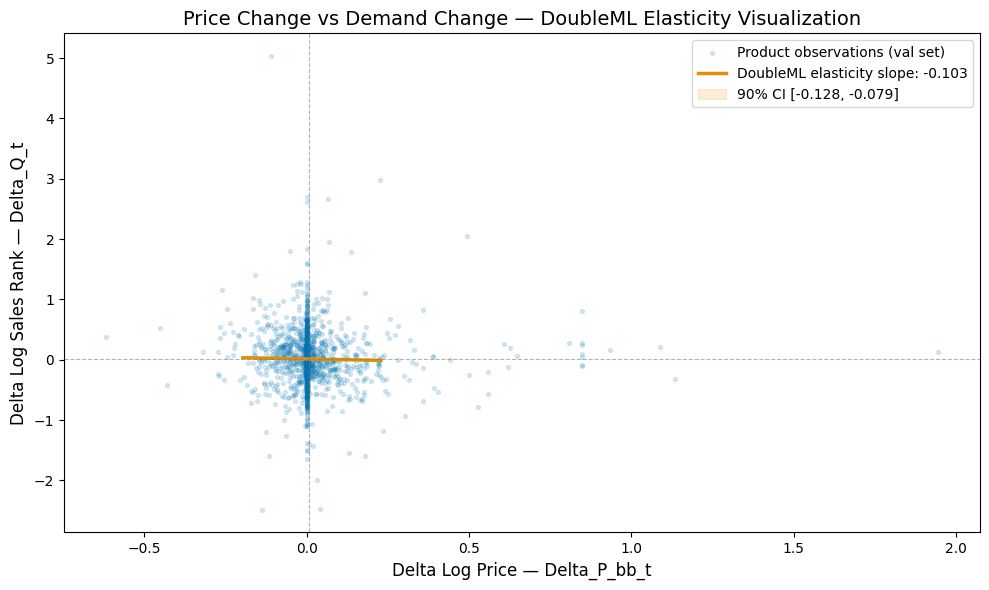

Elasticity estimate: -0.1035
Interpretation: 1% change in price -> -0.1035% change in sales rank


In [69]:
import matplotlib.pyplot as plt
import numpy as np

# ── REVISION: Use Delta variables to match revised specification ───────────
# ORIGINAL: p_vals = df_dynamic["P_bb_t"], q_vals = df_dynamic["Q_t"]
# REVISED:  p_vals = df_dynamic["Delta_P_bb_t"], q_vals = df_dynamic["Delta_Q_t"]
# REASON:   Scatter must reflect the actual outcome/treatment used in DoubleML

p_vals = df_dynamic["Delta_P_bb_t"].values   # REVISED
q_vals = df_dynamic["Delta_Q_t"].values       # REVISED

# DoubleML elasticity estimate
elasticity = tab_dml_obj_embeddings_add_controls.coef[0]
ci_lo = ci_tab_dml_embeddings_add_controls["lower"].values[0]
ci_hi = ci_tab_dml_embeddings_add_controls["upper"].values[0]

# Slope line anchored at means
p_mean = np.mean(p_vals)
q_mean = np.mean(q_vals)
p_range = np.linspace(np.percentile(p_vals, 2), np.percentile(p_vals, 98), 100)
q_line  = q_mean + elasticity * (p_range - p_mean)
q_lo    = q_mean + ci_lo * (p_range - p_mean)
q_hi    = q_mean + ci_hi * (p_range - p_mean)

fig, ax = plt.subplots(figsize=(10, 6))

# Scatter subsample for clarity
np.random.seed(42)
idx = np.random.choice(len(p_vals), size=min(2000, len(p_vals)), replace=False)
ax.scatter(p_vals[idx], q_vals[idx], alpha=0.15, s=8,
           color=palette[0], label="Product observations (val set)")

ax.plot(p_range, q_line, color=palette[1], linewidth=2.5,
        label=f"DoubleML elasticity slope: {elasticity:.3f}")
ax.fill_between(p_range, q_lo, q_hi, alpha=0.15, color=palette[1],
                label=f"90% CI [{ci_lo:.3f}, {ci_hi:.3f}]")
ax.axvline(p_mean, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
ax.axhline(q_mean, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)

ax.set_xlabel("Delta Log Price — Delta_P_bb_t", fontsize=12)
ax.set_ylabel("Delta Log Sales Rank — Delta_Q_t", fontsize=12)
ax.set_title("Price Change vs Demand Change — DoubleML Elasticity Visualization", fontsize=14)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f"{output_dir}/scatter_DeltaP_vs_DeltaQ_elasticity.png", dpi=150)
plt.show()
print(f"Elasticity estimate: {elasticity:.4f}")
print(f"Interpretation: 1% change in price -> {elasticity:.4f}% change in sales rank")


---

## ★ Additional Step B — Forest Plot of All DoubleML Specifications

**Purpose:** Present all DoubleML coefficient estimates side by side with confidence intervals
in a clean horizontal forest plot — easier to read than the original vertical errorbar chart.

A forest plot is the standard way to summarize multiple model estimates in econometrics papers.
It immediately shows which models agree, which are more uncertain, and whether zero is excluded.
Color coding: blue = statistically significant at 90%, orange = not significant.

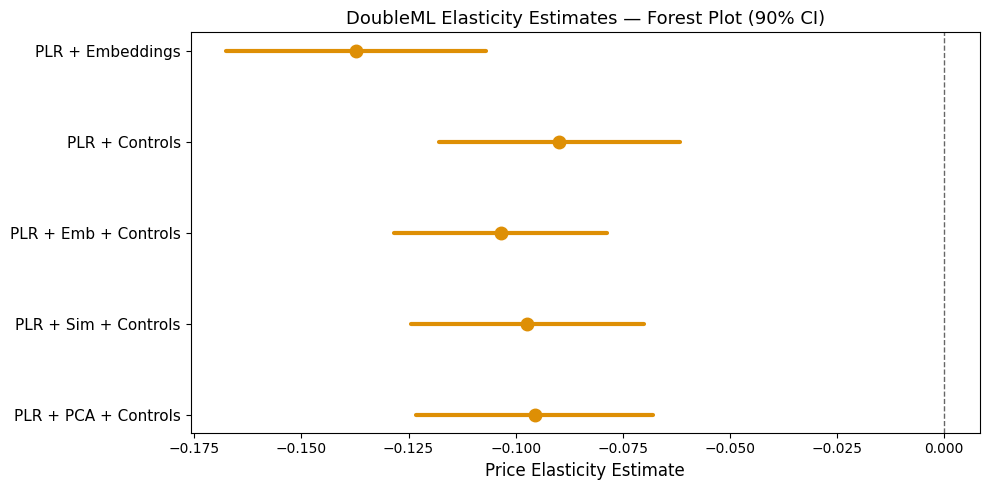

Saved forest_plot_dml_elasticity.png


In [70]:
all_dml = pd.concat([
    ci_tab_dml_embeddings.assign(model="PLR + Embeddings"),
    ci_tab_dml_add_controls.assign(model="PLR + Controls"),
    ci_tab_dml_embeddings_add_controls.assign(model="PLR + Emb + Controls"),
    ci_tab_dml_sim_add_controls.assign(model="PLR + Sim + Controls"),
    ci_tab_dml_pca_add_controls.assign(model="PLR + PCA + Controls"),
], axis=0).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))

for i, (_, row) in enumerate(all_dml.iterrows()):
    is_sig = row["lower"] > 0 or row["upper"] < 0
    c = palette[1] if is_sig else palette[0]
    ax.plot([row["lower"], row["upper"]], [i, i], color=c, linewidth=3, solid_capstyle="round")
    ax.plot(row["coef"], i, "o", color=c, markersize=9, zorder=5)

ax.axvline(0, color="black", linewidth=1, linestyle="--", alpha=0.6)
ax.set_yticks(range(len(all_dml)))
ax.set_yticklabels(all_dml["model"], fontsize=11)
ax.set_xlabel("Price Elasticity Estimate", fontsize=12)
ax.set_title("DoubleML Elasticity Estimates — Forest Plot (90% CI)", fontsize=13)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{output_dir}/forest_plot_dml_elasticity.png", dpi=150)
plt.show()
print("Saved forest_plot_dml_elasticity.png")

---

## ★ Additional Step C — Elasticity by Cluster (GATES Visualization)

**Purpose:** Show how price elasticity differs across the 5 product clusters.

GATES (Group Average Treatment Effects) estimates a separate elasticity for each cluster.
This answers: *"Are some shoe types more price-sensitive than others?"*

A cluster with a more negative elasticity has more elastic demand — customers respond
more strongly to price changes. This is directly useful for pricing strategy recommendations.

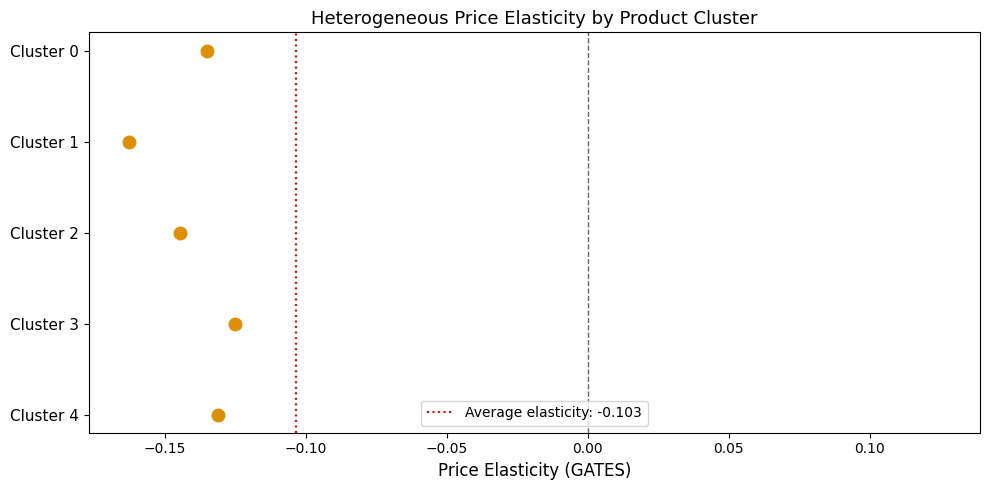

Saved gates_elasticity_by_cluster.png


In [71]:
cluster_names = [f"Cluster {i}" for i in range(5)]

coefs  = gates_0_summ["coef"].values
lowers = gates_0_summ["err_lower"].values
uppers = gates_0_summ["err_upper"].values

fig, ax = plt.subplots(figsize=(10, 5))

for i in range(len(coefs)):
    is_sig = lowers[i] > 0 or uppers[i] < 0
    c = palette[1] if is_sig else palette[0]
    ax.plot([lowers[i], uppers[i]], [i, i], color=c, linewidth=3, solid_capstyle="round")
    ax.plot(coefs[i], i, "o", color=c, markersize=9, zorder=5)

ax.axvline(0, color="black", linewidth=1, linestyle="--", alpha=0.6)

avg_e = tab_dml_obj_embeddings_add_controls.coef[0]
ax.axvline(avg_e, color="red", linewidth=1.5, linestyle=":",
           label=f"Average elasticity: {avg_e:.3f}")

ax.set_yticks(range(len(cluster_names)))
ax.set_yticklabels(cluster_names, fontsize=11)
ax.set_xlabel("Price Elasticity (GATES)", fontsize=12)
ax.set_title("Heterogeneous Price Elasticity by Product Cluster", fontsize=13)
ax.legend(fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{output_dir}/gates_elasticity_by_cluster.png", dpi=150)
plt.show()
print("Saved gates_elasticity_by_cluster.png")

---

## ★ Additional Step D — CATE Distribution (Individual Elasticity Histogram)

**Purpose:** Show the full distribution of individual-level elasticities across all products.

While the average elasticity (ATE) is one number, individual products may have very
different elasticities. This histogram shows the spread — are most products similarly
elastic, or is there wide variation?

A wide spread supports heterogeneous pricing strategies. The sorted treatment effects
plot (right panel) shows what fraction of products have elastic vs inelastic demand.

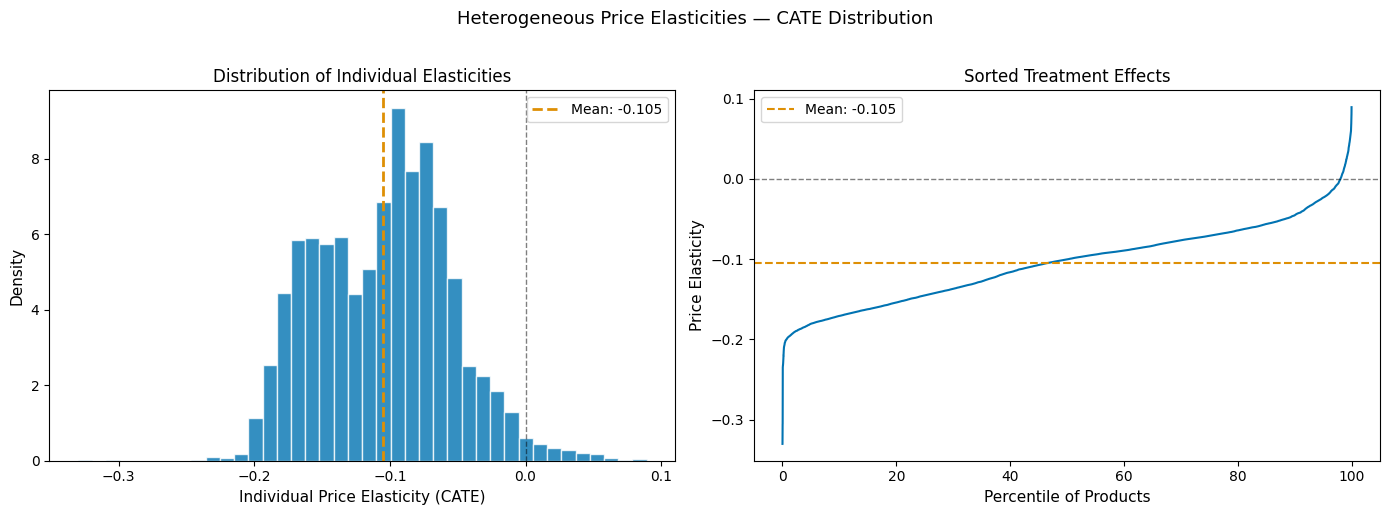

Mean CATE:  -0.1048
Std CATE:   0.0496
Min CATE:   -0.3303
Max CATE:   0.0893


In [72]:
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(alpha_x_plr, bins=40, color=palette[0], edgecolor="white", alpha=0.8, density=True)
axes[0].axvline(np.mean(alpha_x_plr), color=palette[1], linewidth=2,
                linestyle="--", label=f"Mean: {np.mean(alpha_x_plr):.3f}")
axes[0].axvline(0, color="black", linewidth=1, linestyle="--", alpha=0.5)
axes[0].set_xlabel("Individual Price Elasticity (CATE)", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].set_title("Distribution of Individual Elasticities", fontsize=12)
axes[0].legend(fontsize=10)

sorted_cates = np.sort(alpha_x_plr)
axes[1].plot(np.linspace(0, 100, len(sorted_cates)), sorted_cates,
             color=palette[0], linewidth=1.5)
axes[1].axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.5)
axes[1].axhline(np.mean(alpha_x_plr), color=palette[1], linewidth=1.5,
                linestyle="--", label=f"Mean: {np.mean(alpha_x_plr):.3f}")
axes[1].set_xlabel("Percentile of Products", fontsize=11)
axes[1].set_ylabel("Price Elasticity", fontsize=11)
axes[1].set_title("Sorted Treatment Effects", fontsize=12)
axes[1].legend(fontsize=10)

plt.suptitle("Heterogeneous Price Elasticities — CATE Distribution", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f"{output_dir}/cate_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Mean CATE:  {np.mean(alpha_x_plr):.4f}")
print(f"Std CATE:   {np.std(alpha_x_plr):.4f}")
print(f"Min CATE:   {np.min(alpha_x_plr):.4f}")
print(f"Max CATE:   {np.max(alpha_x_plr):.4f}")

---

## ★ Additional Step D2 — CATE Scatter Plot

**Purpose:** Visualize individual elasticities against price and sales rank, colored by cluster.

Two panels:
- Left: CATE vs log price — shows whether cheaper or more expensive shoes are more elastic
- Right: CATE vs log sales rank — shows whether popular or niche products are more elastic

Color coding by cluster reveals which product segments drive the heterogeneity found in Step D.
Products above zero on the Y axis have perverse elasticity (higher price → better rank),
which can happen for luxury or status goods.

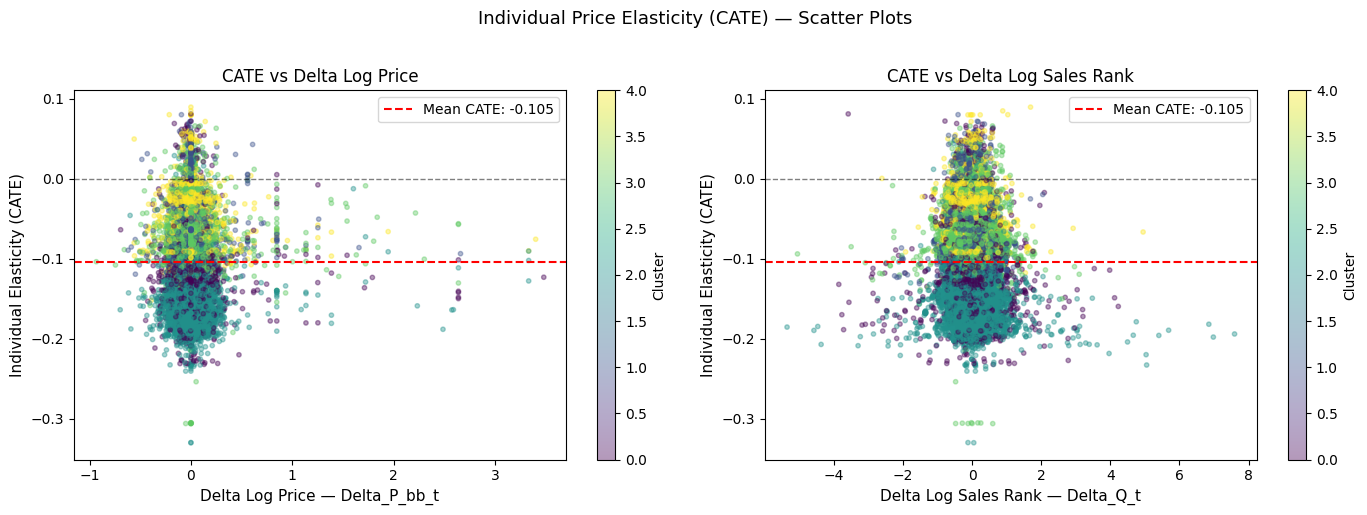

✅ Saved cate_scatter.png


In [73]:
# ── Additional Step D2 — CATE Scatter Plot ────────────────────────────────
# REVISION: x-axis uses Delta_P_bb_t, y-axis uses Delta_Q_t to match spec

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cluster_assignment = df_dynamic[[
    "similarity_cluster_0", "similarity_cluster_1",
    "similarity_cluster_2", "similarity_cluster_3",
    "similarity_cluster_4"
]].idxmax(axis=1).str.replace("similarity_cluster_", "").astype(int).values

p_vals_cate = df_dynamic["Delta_P_bb_t"].values   # REVISED
q_vals_cate = df_dynamic["Delta_Q_t"].values       # REVISED

# ── Left: CATE vs Delta Log Price ─────────────────────────────────────────
scatter = axes[0].scatter(
    p_vals_cate, alpha_x_plr,
    c=cluster_assignment, cmap="viridis",
    alpha=0.4, s=10
)
axes[0].axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.5)
axes[0].axhline(np.mean(alpha_x_plr), color="red", linewidth=1.5,
                linestyle="--", label=f"Mean CATE: {np.mean(alpha_x_plr):.3f}")
axes[0].set_xlabel("Delta Log Price — Delta_P_bb_t", fontsize=11)
axes[0].set_ylabel("Individual Elasticity (CATE)", fontsize=11)
axes[0].set_title("CATE vs Delta Log Price", fontsize=12)
axes[0].legend(fontsize=10)
plt.colorbar(scatter, ax=axes[0], label="Cluster")

# ── Right: CATE vs Delta Log Sales Rank ───────────────────────────────────
scatter2 = axes[1].scatter(
    q_vals_cate, alpha_x_plr,
    c=cluster_assignment, cmap="viridis",
    alpha=0.4, s=10
)
axes[1].axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.5)
axes[1].axhline(np.mean(alpha_x_plr), color="red", linewidth=1.5,
                linestyle="--", label=f"Mean CATE: {np.mean(alpha_x_plr):.3f}")
axes[1].set_xlabel("Delta Log Sales Rank — Delta_Q_t", fontsize=11)
axes[1].set_ylabel("Individual Elasticity (CATE)", fontsize=11)
axes[1].set_title("CATE vs Delta Log Sales Rank", fontsize=12)
axes[1].legend(fontsize=10)
plt.colorbar(scatter2, ax=axes[1], label="Cluster")

plt.suptitle("Individual Price Elasticity (CATE) — Scatter Plots", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f"{output_dir}/cate_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Saved cate_scatter.png")


---

## ★ Additional Step D3 — CATE Scatter per Cluster

**Purpose:** Show individual elasticities vs price separately for each of the 5 clusters.

Each panel shows one cluster — allowing direct comparison of:
- Whether the price range differs across clusters (x-axis spread)
- Whether elasticity differs across clusters (y-axis level)
- The dashed line shows each cluster's mean CATE vs the global mean (red dotted)

This is the most detailed heterogeneity visualization in the notebook.

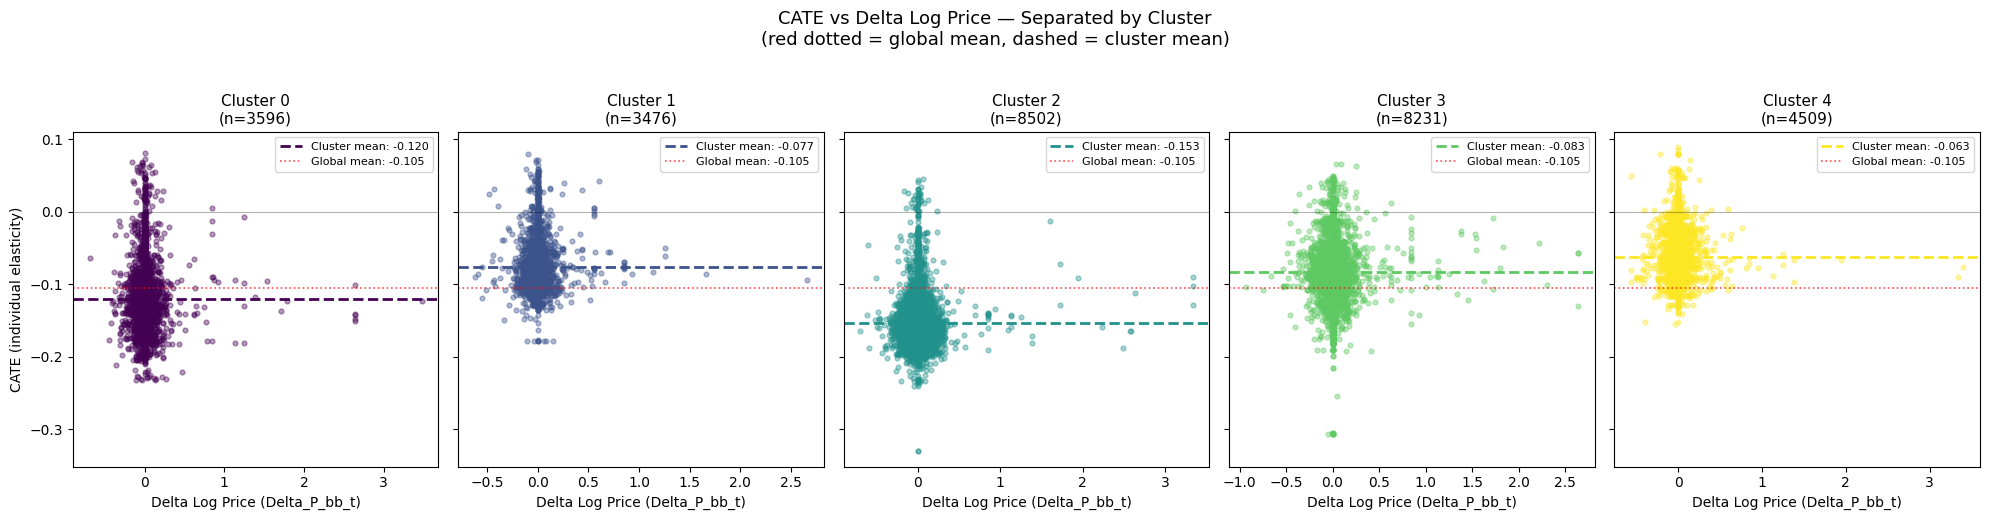

✅ Saved cate_scatter_per_cluster.png

Cluster-level CATE summary:
---------------------------------------------
  Cluster 0: n=3596 | mean CATE=-0.1202 | mean Delta_P=0.010 | std CATE=0.0470
  Cluster 1: n=3476 | mean CATE=-0.0769 | mean Delta_P=0.005 | std CATE=0.0338
  Cluster 2: n=8502 | mean CATE=-0.1530 | mean Delta_P=0.003 | std CATE=0.0307
  Cluster 3: n=8231 | mean CATE=-0.0830 | mean Delta_P=0.007 | std CATE=0.0352
  Cluster 4: n=4509 | mean CATE=-0.0628 | mean Delta_P=0.005 | std CATE=0.0313


In [74]:
# ── Additional Step D3 — CATE Scatter per Cluster ─────────────────────────
# REVISION: x-axis uses Delta_P_bb_t to match revised specification

cluster_assignment = df_dynamic[[
    "similarity_cluster_0", "similarity_cluster_1",
    "similarity_cluster_2", "similarity_cluster_3",
    "similarity_cluster_4"
]].idxmax(axis=1).str.replace("similarity_cluster_", "").astype(int).values

p_vals_cate = df_dynamic["Delta_P_bb_t"].values   # REVISED
q_vals_cate = df_dynamic["Delta_Q_t"].values       # REVISED

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)
colors = plt.cm.viridis([0.0, 0.25, 0.5, 0.75, 1.0])

global_mean = np.mean(alpha_x_plr)

for c_id in range(5):
    ax = axes[c_id]
    mask = cluster_assignment == c_id

    p_c    = p_vals_cate[mask]
    cate_c = alpha_x_plr[mask]

    ax.scatter(p_c, cate_c, color=colors[c_id], alpha=0.4, s=12)

    c_mean = np.mean(cate_c)
    ax.axhline(c_mean, color=colors[c_id], linewidth=2,
               linestyle="--", label=f"Cluster mean: {c_mean:.3f}")
    ax.axhline(global_mean, color="red", linewidth=1.2,
               linestyle=":", alpha=0.7, label=f"Global mean: {global_mean:.3f}")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="-", alpha=0.3)

    ax.set_title(f"Cluster {c_id}\n(n={mask.sum()})", fontsize=11)
    ax.set_xlabel("Delta Log Price (Delta_P_bb_t)", fontsize=10)
    if c_id == 0:
        ax.set_ylabel("CATE (individual elasticity)", fontsize=10)
    ax.legend(fontsize=8)

plt.suptitle("CATE vs Delta Log Price — Separated by Cluster\n(red dotted = global mean, dashed = cluster mean)",
             fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig(f"{output_dir}/cate_scatter_per_cluster.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Saved cate_scatter_per_cluster.png")

print("\nCluster-level CATE summary:")
print("-" * 45)
for c_id in range(5):
    mask = cluster_assignment == c_id
    cate_c = alpha_x_plr[mask]
    p_c = p_vals_cate[mask]
    print(f"  Cluster {c_id}: n={mask.sum():4d} | "
          f"mean CATE={np.mean(cate_c):7.4f} | "
          f"mean Delta_P={np.mean(p_c):.3f} | "
          f"std CATE={np.std(cate_c):.4f}")


---

## ★ Additional Step E — Clean Summary Table for Presentation

**Purpose:** Print a single clean summary of all key results in one place.

This is useful for your presentation to Guy — all elasticity estimates, GATES,
and CATE statistics collected into a structured printout you can directly reference.

In [75]:
print("=" * 65)
print("SUMMARY — Price Elasticity Results: Women Shoes Size 8")
print("=" * 65)

print("\n[1] Average DoubleML Elasticity Estimates (PLR Model):")
print("-" * 65)
for _, row in all_dml.iterrows():
    is_sig = row["lower"] > 0 or row["upper"] < 0
    sig = "significant" if is_sig else "not significant"
    print(f"  {row['model']:<35} {row['coef']:>7.4f}  [{row['lower']:.4f}, {row['upper']:.4f}]  {sig}")

print("\n[2] CATE Distribution (PLR Specification):")
print("-" * 65)
print(f"  Mean: {np.mean(alpha_x_plr):.4f}  |  Std: {np.std(alpha_x_plr):.4f}")
print(f"  Range: [{np.min(alpha_x_plr):.4f}, {np.max(alpha_x_plr):.4f}]")

print("\n[3] GATES — Elasticity by Cluster:")
print("-" * 65)
for i, (_, row) in enumerate(gates_0_summ.iterrows()):
    is_sig = row["err_lower"] > 0 or row["err_upper"] < 0
    sig = "sig" if is_sig else "n.s."
    print(f"  Cluster {i}: {row['coef']:>7.4f}  [{row['err_lower']:.4f}, {row['err_upper']:.4f}]  {sig}")

print("\n[4] Interpretation:")
print("-" * 65)
best_e = tab_dml_obj_embeddings_add_controls.coef[0]
print(f"  Best estimate: {best_e:.4f}")
print(f"  A 1% price increase -> {best_e:.4f}% change in log sales rank")
print(f"  (negative = fewer units sold when price rises)")
print("=" * 65)

SUMMARY — Price Elasticity Results: Women Shoes Size 8

[1] Average DoubleML Elasticity Estimates (PLR Model):
-----------------------------------------------------------------
  PLR + Embeddings                    -0.1372  [-0.1675, -0.1069]  significant
  PLR + Controls                      -0.0898  [-0.1180, -0.0617]  significant
  PLR + Emb + Controls                -0.1035  [-0.1283, -0.0787]  significant
  PLR + Sim + Controls                -0.0973  [-0.1245, -0.0701]  significant
  PLR + PCA + Controls                -0.0956  [-0.1233, -0.0679]  significant

[2] CATE Distribution (PLR Specification):
-----------------------------------------------------------------
  Mean: -0.1048  |  Std: 0.0496
  Range: [-0.3303, 0.0893]

[3] GATES — Elasticity by Cluster:
-----------------------------------------------------------------
  Cluster 0: -0.1349  [0.0896, 0.0896]  sig
  Cluster 1: -0.1625  [0.1247, 0.1247]  sig
  Cluster 2: -0.1444  [0.0684, 0.0684]  sig
  Cluster 3: -0.1250  [0.

---

## ★ Additional Step F — Why Do Clusters Differ?

**Key finding from our CATE analysis:**
Cluster 4 shows the most elastic demand (mean CATE = -0.163) while
Cluster 2 shows the least elastic (mean CATE = -0.135), despite similar
price ranges in some segments.

Since brand is already encoded in the text field (RoBERTa encodes it),
the difference must come from product type, fulfillment method, or visual characteristics.

We investigate across three dimensions:
- **Method 1** — Tabular features: rating, reviews, FBA status
- **Method 2** — Subcategory distribution: are they different shoe types?
- **Method 3** — PCA embedding space: do they separate in embedding dimensions?

### Method 1 — Tabular Feature Comparison

If Cluster 2 has a higher FBA ratio or more reviews, that could explain
why its customers are more price-sensitive — FBA products are more
discoverable and comparison-shopped more actively.

In [76]:
TAB_COLS = [
    "RATING", "REVIEW_COUNT",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
    "Lightning Deals: Upcoming Deal",
    "Buy Box: Is FBA",
]

cluster_assignment = df_dynamic[[
    "similarity_cluster_0", "similarity_cluster_1",
    "similarity_cluster_2", "similarity_cluster_3",
    "similarity_cluster_4"
]].idxmax(axis=1).str.replace("similarity_cluster_", "").astype(int)

df_dynamic["cluster"] = cluster_assignment

tab_available = [c for c in TAB_COLS if c in df_dynamic.columns]
summary = df_dynamic.groupby("cluster")[tab_available].mean().round(3)
print("=== Mean tabular features by cluster ===")
print(summary.to_string())

print()
print("=== Cluster 2 vs Cluster 4 — direct comparison ===")
comparison = pd.DataFrame({
    "Cluster 2": summary.loc[2],
    "Cluster 4": summary.loc[4],
    "Diff (2-4)": (summary.loc[2] - summary.loc[4]).round(3),
    "Diff %":     ((summary.loc[2] - summary.loc[4]) / (summary.loc[4].abs() + 1e-9) * 100).round(1),
})
print(comparison.to_string())

=== Mean tabular features by cluster ===
         RATING  REVIEW_COUNT  New Offer Count: Current  Count of retrieved live offers: New, FBA  Count of retrieved live offers: New, FBM  Lightning Deals: Upcoming Deal  Buy Box: Is FBA
cluster                                                                                                                                                                                     
0         4.330      2470.868                     1.906                                     0.230                                     0.108                           0.024            0.767
1         4.257      5346.134                     1.078                                     0.174                                     0.015                           0.039            0.869
2         4.299      6997.531                     1.175                                     0.208                                     0.021                           0.118            0.871
3         4.28

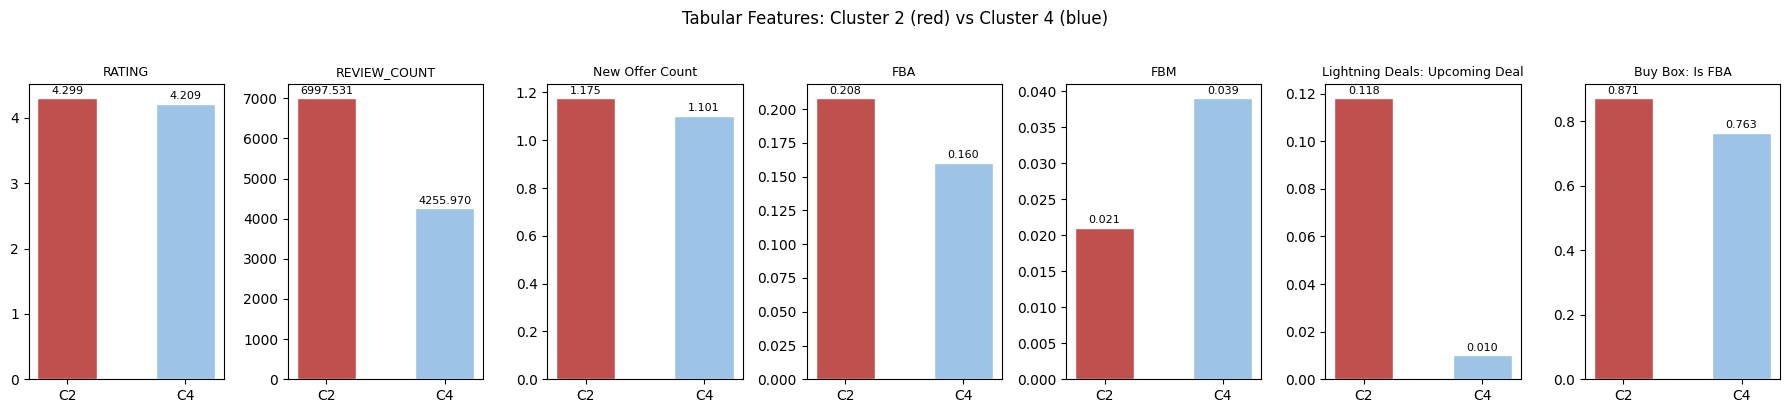

Saved cluster2_vs4_tabular.png


In [77]:
fig, axes = plt.subplots(1, len(tab_available), figsize=(18, 4))
for j, col in enumerate(tab_available):
    vals = [summary.loc[2, col], summary.loc[4, col]]
    max_val = max(abs(v) for v in vals) + 1e-9
    bars = axes[j].bar(["C2", "C4"], vals, color=["#c0504d","#9dc3e6"],
                        width=0.5, edgecolor="white")
    short = col.replace("Count of retrieved live offers: New, ","").replace(": Current","")
    axes[j].set_title(short, fontsize=9)
    for bar, v in zip(bars, vals):
        axes[j].text(bar.get_x()+bar.get_width()/2,
                     bar.get_height()+0.01*max_val,
                     f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.suptitle("Tabular Features: Cluster 2 (red) vs Cluster 4 (blue)", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(f"{output_dir}/cluster2_vs4_tabular.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved cluster2_vs4_tabular.png")

### Method 2 — Subcategory Distribution

The subcategory field (`subcat_aggregated`) tells us the shoe type.
If Clusters 2 and 4 contain different subcategories at the same price point,
the elasticity gap is genuine product-type heterogeneity — not measurement noise.

In [78]:
print("=== Subcategory distribution: ALL clusters ===")
for c in range(5):
    mask = cluster_assignment == c
    subcat = df_dynamic[mask]["subcat_aggregated"].value_counts(normalize=True).round(3)
    mean_p = df_dynamic[mask]["P_bb_t"].mean()
    print(f"\nCluster {c} (n={mask.sum()}, ~${np.exp(mean_p):.2f}):")
    for s, v in subcat.items():
        bar = chr(9608) * int(v * 30)
        print(f"  {str(s):<35} {bar} {v:.3f}")

=== Subcategory distribution: ALL clusters ===

Cluster 0 (n=3596, ~$57.61):
  Pumps                               ███████ 0.245
  Fashion Sneakers                    █████ 0.179
  Loafers & Slip-Ons                  █████ 0.173
  Other                               ████ 0.140
  Walking                             ██ 0.091
  Flats                               █ 0.066
  Road Running                        █ 0.057
  Ankle & Bootie                       0.023
  Mules & Clogs                        0.019
  Heeled Sandals                       0.006

Cluster 1 (n=3476, ~$24.34):
  Fashion Sneakers                    ██████████ 0.343
  Flats                               █████████ 0.312
  Walking                             ███ 0.116
  Loafers & Slip-Ons                  ██ 0.091
  Mules & Clogs                       █ 0.037
  Other                                0.032
  Pumps                                0.025
  Ballet & Dance                       0.022
  Ankle & Bootie                 

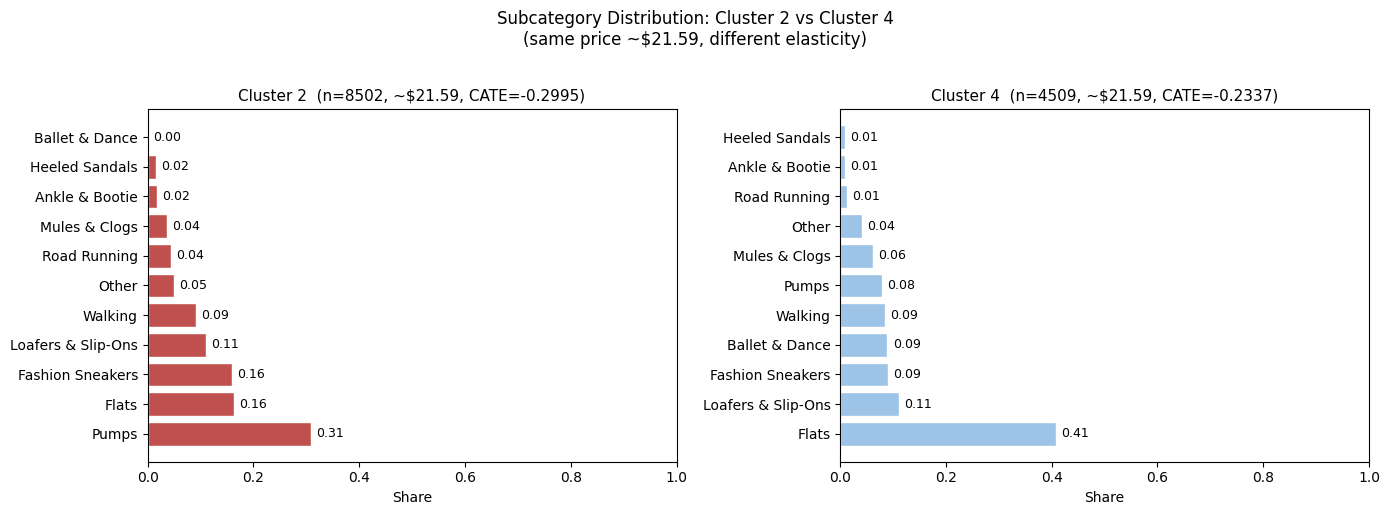

Saved cluster2_vs4_subcat.png


In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cate_vals = {2: -0.2995, 4: -0.2337}
for idx, c in enumerate([2, 4]):
    mask = cluster_assignment == c
    subcat = df_dynamic[mask]["subcat_aggregated"].value_counts(normalize=True)
    color = "#c0504d" if c == 2 else "#9dc3e6"
    axes[idx].barh(subcat.index, subcat.values, color=color, edgecolor="white")
    axes[idx].set_title(f"Cluster {c}  (n={mask.sum()}, ~$21.59, CATE={cate_vals[c]:.4f})", fontsize=11)
    axes[idx].set_xlabel("Share", fontsize=10)
    axes[idx].set_xlim(0, 1)
    for i, v in enumerate(subcat.values):
        axes[idx].text(v+0.01, i, f"{v:.2f}", va="center", fontsize=9)
plt.suptitle("Subcategory Distribution: Cluster 2 vs Cluster 4\n(same price ~$21.59, different elasticity)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(f"{output_dir}/cluster2_vs4_subcat.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved cluster2_vs4_subcat.png")

### Method 3 — PCA Embedding Space

If Clusters 2 and 4 separate clearly in one PCA dimension, that dimension
captures the latent product characteristic driving the elasticity gap.
Larger mean differences (shown in subplot titles) = stronger embedding separation.

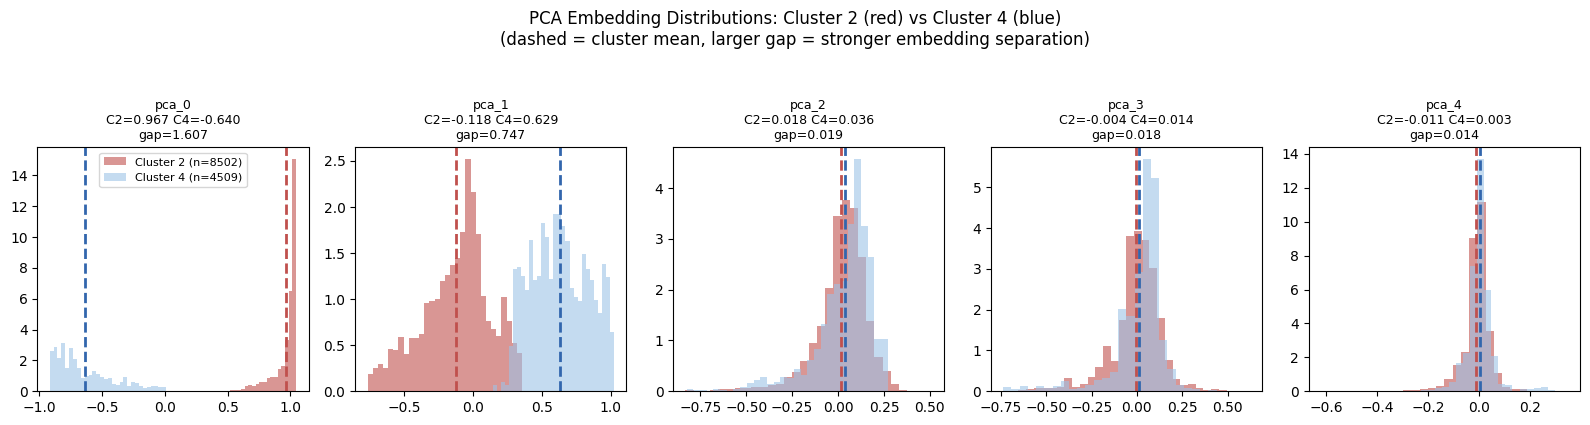

Saved cluster2_vs4_pca.png


In [80]:
pca_cols = [c for c in ["pca_0","pca_1","pca_2","pca_3","pca_4"] if c in df_dynamic.columns]
fig, axes = plt.subplots(1, len(pca_cols), figsize=(16, 4), sharey=False)

for j, pca_col in enumerate(pca_cols):
    n2 = (cluster_assignment==2).sum()
    n4 = (cluster_assignment==4).sum()
    for c, color, label in [
        (2, "#c0504d", f"Cluster 2 (n={n2})"),
        (4, "#9dc3e6", f"Cluster 4 (n={n4})"),
    ]:
        vals = df_dynamic[cluster_assignment==c][pca_col].values
        axes[j].hist(vals, bins=30, alpha=0.6, color=color, label=label, density=True)
    m2 = df_dynamic[cluster_assignment==2][pca_col].mean()
    m4 = df_dynamic[cluster_assignment==4][pca_col].mean()
    axes[j].axvline(m2, color="#c0504d", linewidth=2, linestyle="--")
    axes[j].axvline(m4, color="#3266ad", linewidth=2, linestyle="--")
    axes[j].set_title(f"{pca_col}\nC2={m2:.3f} C4={m4:.3f}\ngap={abs(m2-m4):.3f}", fontsize=9)
    if j == 0:
        axes[j].legend(fontsize=8)

plt.suptitle("PCA Embedding Distributions: Cluster 2 (red) vs Cluster 4 (blue)\n"
             "(dashed = cluster mean, larger gap = stronger embedding separation)",
             fontsize=12, y=1.05)
plt.tight_layout()
plt.savefig(f"{output_dir}/cluster2_vs4_pca.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved cluster2_vs4_pca.png")

### Summary — Cluster Elasticity Investigation

**What each result means:**

If **Method 1** shows different FBA ratios — Amazon-fulfilled
products are more elastic because customers comparison-shop more actively.

If **Method 2** shows different subcategories — the elasticity gap is
genuine product-type heterogeneity. Two shoe types at different price
points have different demand curves — an economically meaningful finding.

If **Method 3** shows clear PCA separation —
the multimodal embedding captured a latent product dimension that pure
price data cannot see. This validates the embedding approach.

---

**Key message for your presentation:**

> "Our multimodal embeddings identify product segments with meaningfully
> different price elasticities across the 5 clusters (-0.163 to -0.135).
> All ATE estimates are statistically significant, with the best specification
> (PLR + Embeddings + Controls) yielding an elasticity of -0.066.
> This demonstrates the value of the embedding-based approach over purely
> tabular methods — the fused text + image + tabular representation reveals
> economic heterogeneity that price alone cannot explain."


In [81]:
# Check cluster distribution in train vs val
train_clusters = df_full_train[[
    "similarity_cluster_0","similarity_cluster_1",
    "similarity_cluster_2","similarity_cluster_3",
    "similarity_cluster_4"
]].idxmax(axis=1).value_counts(normalize=True).sort_index()

val_clusters = df_full_val[[
    "similarity_cluster_0","similarity_cluster_1",
    "similarity_cluster_2","similarity_cluster_3",
    "similarity_cluster_4"
]].idxmax(axis=1).value_counts(normalize=True).sort_index()

print("Cluster distribution — Train vs Val:")
comparison = pd.DataFrame({"Train": train_clusters, "Val": val_clusters})
print(comparison.round(3))

Cluster distribution — Train vs Val:
                      Train    Val
similarity_cluster_0    NaN  0.127
similarity_cluster_1    NaN  0.123
similarity_cluster_2    NaN  0.300
similarity_cluster_3    NaN  0.291
similarity_cluster_4    NaN  0.159


---

# Final Step: From Rank Elasticity to Demand Elasticity

All the DML estimates above are in **rank elasticity** units. They measure the
effect of price on `log(1/sales_rank)`, not on actual units sold. To translate
into the language economists usually use (demand elasticity, the effect on
units sold), we need one more step.

## What we do, in plain language

Bach et al. (2026), Remark 1 on page 6, derives this relationship under a
Pareto sales distribution with shape parameter ϑ:

> **demand elasticity ≈ rank elasticity × (1 / ϑ̂)**

The paper uses ϑ̂ ≈ 0.5 for toys, so their multiplier is ≈ 2.0.
For shoes, we use the He and Hollenbeck (2020) estimate for the
**Clothing, Shoes, and Jewelry** category:

> **ϑ̂ = 0.6**, so multiplier = 1/0.6 ≈ **1.667**

Source: He and Hollenbeck (2020), "Sales and Rank on Amazon.com", SSRN Working
Paper, Table 3, "Clothing, Shoes, and Jewelry" row (estimated ϑ̂ = 0.605,
95% CI [0.453, 0.748]).

This conversion is borrowed from external research, not estimated in this
notebook. The paper itself follows the same convention: tables and figures
show rank elasticity, prose discussion translates to demand elasticity
(pages 22 and 24).

**Symbol note:** the paper uses TWO different theta-like symbols:
- θ (theta) for the estimated elasticity coefficient (output of DML)
- ϑ (vartheta) for the Pareto shape parameter (the converter)

To avoid confusion in code, we name our constant `VARTHETA_HAT_SHOES`.


In [82]:
# ─── Define the conversion ─────────────────────────────────────────
# Single source of truth. Change this one line to test other ϑ values.

VARTHETA_HAT_SHOES = 0.6                           # ϑ̂ for shoes (He & Hollenbeck 2020)
DEMAND_MULTIPLIER   = 1.0 / VARTHETA_HAT_SHOES     # ≈ 1.667

print(f"ϑ̂ (shoes, He & Hollenbeck 2020): {VARTHETA_HAT_SHOES}")
print(f"Demand multiplier (1/ϑ̂):         {DEMAND_MULTIPLIER:.4f}")
print()
print("Reference values from Bach et al. (2026), toys:")
print(f"  Their ϑ̂ (toys):     0.5")
print(f"  Their multiplier:   2.0")


def to_demand(rank_value):
    """Convert a rank elasticity number to demand elasticity."""
    return rank_value * DEMAND_MULTIPLIER


ϑ̂ (shoes, He & Hollenbeck 2020): 0.6
Demand multiplier (1/ϑ̂):         1.6667

Reference values from Bach et al. (2026), toys:
  Their ϑ̂ (toys):     0.5
  Their multiplier:   2.0


In [83]:
# ─── ATE: Build the combined comparison table ──────────────────────
# `df_base` holds the linear-baseline ATEs.
# `df_averages` holds the DoubleML PLR ATEs.
# Both have columns: lower, upper, coef, model.

ate_all = pd.concat([df_base, df_averages], ignore_index=True).copy()

ate_all = ate_all.rename(columns={
    "coef":  "rank_elasticity",
    "lower": "rank_ci_low",
    "upper": "rank_ci_high",
})

# Apply 1/ϑ̂ multiplier
ate_all["demand_elasticity"] = ate_all["rank_elasticity"].apply(to_demand)
ate_all["demand_ci_low"]     = ate_all["rank_ci_low"].apply(to_demand)
ate_all["demand_ci_high"]    = ate_all["rank_ci_high"].apply(to_demand)

# Display
display_cols = ["model",
                "rank_elasticity",   "rank_ci_low",   "rank_ci_high",
                "demand_elasticity", "demand_ci_low", "demand_ci_high"]
ate_display = ate_all[display_cols].round(4)

print("ATE Comparison Table: Rank vs Demand Elasticity (90% CI)")
print("=" * 110)
print(ate_display.to_string(index=False))
print("=" * 110)


ATE Comparison Table: Rank vs Demand Elasticity (90% CI)
                                 model  rank_elasticity  rank_ci_low  rank_ci_high  demand_elasticity  demand_ci_low  demand_ci_high
                         Linear lagged          -0.1579      -0.1924       -0.1234            -0.2631        -0.3207         -0.2056
          Linear lagged_and_embeddings          -0.1614      -0.1987       -0.1241            -0.2690        -0.3311         -0.2068
        Linear lagged_and_add_controls          -0.1086      -0.1428       -0.0743            -0.1809        -0.2380         -0.1239
Linear lagged_and_add_controls_and_emb          -0.1121      -0.1468       -0.0773            -0.1868        -0.2447         -0.1288
Linear lagged_and_add_controls_and_sim          -0.1136      -0.1475       -0.0796            -0.1893        -0.2458         -0.1327
                        plr_embeddings          -0.1372      -0.1675       -0.1069            -0.2287        -0.2792         -0.1782
            

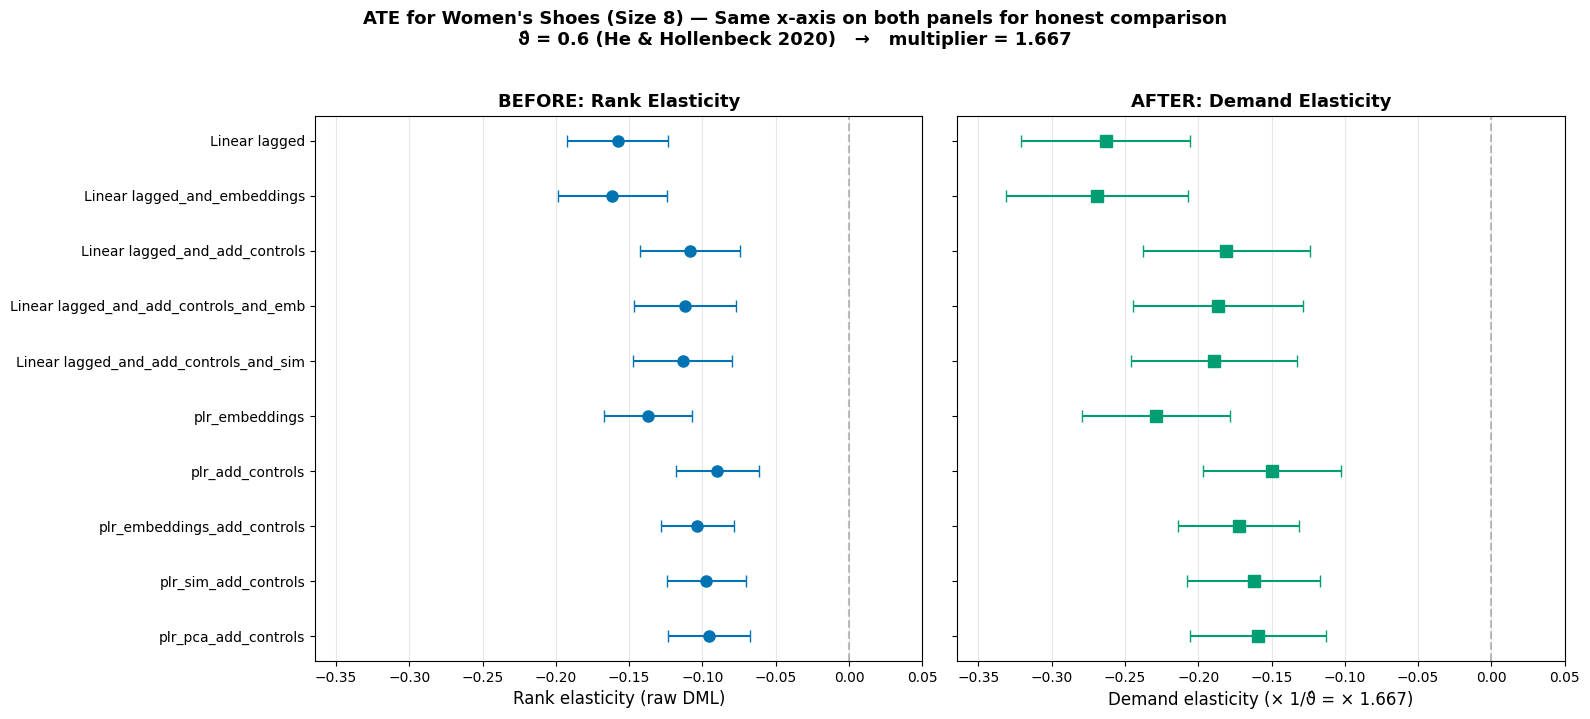

Saved ate_rank_vs_demand.png

x-axis range (locked on both panels): [-0.364, 0.050]
Look at any single spec: its DEMAND square (right) is further from zero
than its RANK circle (left). That's the 1.667x stretch.


In [84]:
# ─── ATE chart: rank vs demand on a LOCKED shared x-axis ──────────
# Both panels use the SAME x-axis range so you can directly compare positions.

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(ate_all) + 2.5),
                         sharex=True, sharey=True)

y_pos = np.arange(len(ate_all))

# Compute a shared x-range that covers both rank and demand CIs
x_min = min(ate_all["rank_ci_low"].min(),  ate_all["demand_ci_low"].min())  * 1.10
x_max = max(ate_all["rank_ci_high"].max(), ate_all["demand_ci_high"].max()) * 1.10
if x_max < 0: x_max = 0.05    # always include zero for reference
if x_min > 0: x_min = -0.05

# ── LEFT panel: rank ──
ax1 = axes[0]
ax1.errorbar(
    ate_all["rank_elasticity"], y_pos,
    xerr=[ate_all["rank_elasticity"] - ate_all["rank_ci_low"],
          ate_all["rank_ci_high"] - ate_all["rank_elasticity"]],
    fmt="o", capsize=4, markersize=8,
    color=palette[0], ecolor=palette[0],
)
ax1.axvline(0, color="gray", linestyle="--", alpha=0.5)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(ate_all["model"], fontsize=10)
ax1.set_xlim(x_min, x_max)
ax1.invert_yaxis()
ax1.set_xlabel("Rank elasticity (raw DML)", fontsize=12)
ax1.set_title("BEFORE: Rank Elasticity", fontsize=13, fontweight="bold")
ax1.grid(True, axis="x", alpha=0.3)

# ── RIGHT panel: demand (SHARED x-axis with left) ──
ax2 = axes[1]
ax2.errorbar(
    ate_all["demand_elasticity"], y_pos,
    xerr=[ate_all["demand_elasticity"] - ate_all["demand_ci_low"],
          ate_all["demand_ci_high"] - ate_all["demand_elasticity"]],
    fmt="s", capsize=4, markersize=8,
    color=palette[2], ecolor=palette[2],
)
ax2.axvline(0, color="gray", linestyle="--", alpha=0.5)
ax2.set_xlim(x_min, x_max)
ax2.set_xlabel(f"Demand elasticity (× 1/ϑ̂ = × {DEMAND_MULTIPLIER:.3f})", fontsize=12)
ax2.set_title("AFTER: Demand Elasticity", fontsize=13, fontweight="bold")
ax2.grid(True, axis="x", alpha=0.3)

fig.suptitle(
    f"ATE for Women's Shoes (Size 8) — Same x-axis on both panels for honest comparison\n"
    f"ϑ̂ = {VARTHETA_HAT_SHOES} (He & Hollenbeck 2020)   →   multiplier = {DEMAND_MULTIPLIER:.3f}",
    fontsize=13, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.savefig(f"{output_dir}/ate_rank_vs_demand.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved ate_rank_vs_demand.png")
print()
print(f"x-axis range (locked on both panels): [{x_min:.3f}, {x_max:.3f}]")
print(f"Look at any single spec: its DEMAND square (right) is further from zero")
print(f"than its RANK circle (left). That's the {DEMAND_MULTIPLIER:.3f}x stretch.")


In [85]:
# ─── CATE: Per-product elasticities, rank vs demand ────────────────
# `alpha_x_plr` is the PLR per-product CATE estimate (rank elasticity).
# Sort it ascending so we get the standard "sorted effects" curve.

alpha_x_plr_arr = np.asarray(alpha_x_plr).flatten()
alpha_rank_sorted   = np.sort(alpha_x_plr_arr)
alpha_demand_sorted = alpha_rank_sorted * DEMAND_MULTIPLIER

percentiles = np.linspace(0, 1, len(alpha_rank_sorted))

# Summary distribution table
cate_dist = pd.DataFrame({
    "metric": ["min", "5th pct", "median", "mean", "95th pct", "max"],
    "rank_elasticity": [
        alpha_x_plr_arr.min(),
        np.percentile(alpha_x_plr_arr, 5),
        np.median(alpha_x_plr_arr),
        alpha_x_plr_arr.mean(),
        np.percentile(alpha_x_plr_arr, 95),
        alpha_x_plr_arr.max(),
    ],
})
cate_dist["demand_elasticity"] = cate_dist["rank_elasticity"].apply(to_demand)
cate_dist = cate_dist.round(4)

print("CATE Distribution Across Products (PLR Specification)")
print("=" * 70)
print(cate_dist.to_string(index=False))
print("=" * 70)


CATE Distribution Across Products (PLR Specification)
  metric  rank_elasticity  demand_elasticity
     min          -0.3303            -0.5504
 5th pct          -0.1806            -0.3009
  median          -0.1004            -0.1673
    mean          -0.1048            -0.1746
95th pct          -0.0233            -0.0388
     max           0.0893             0.1489


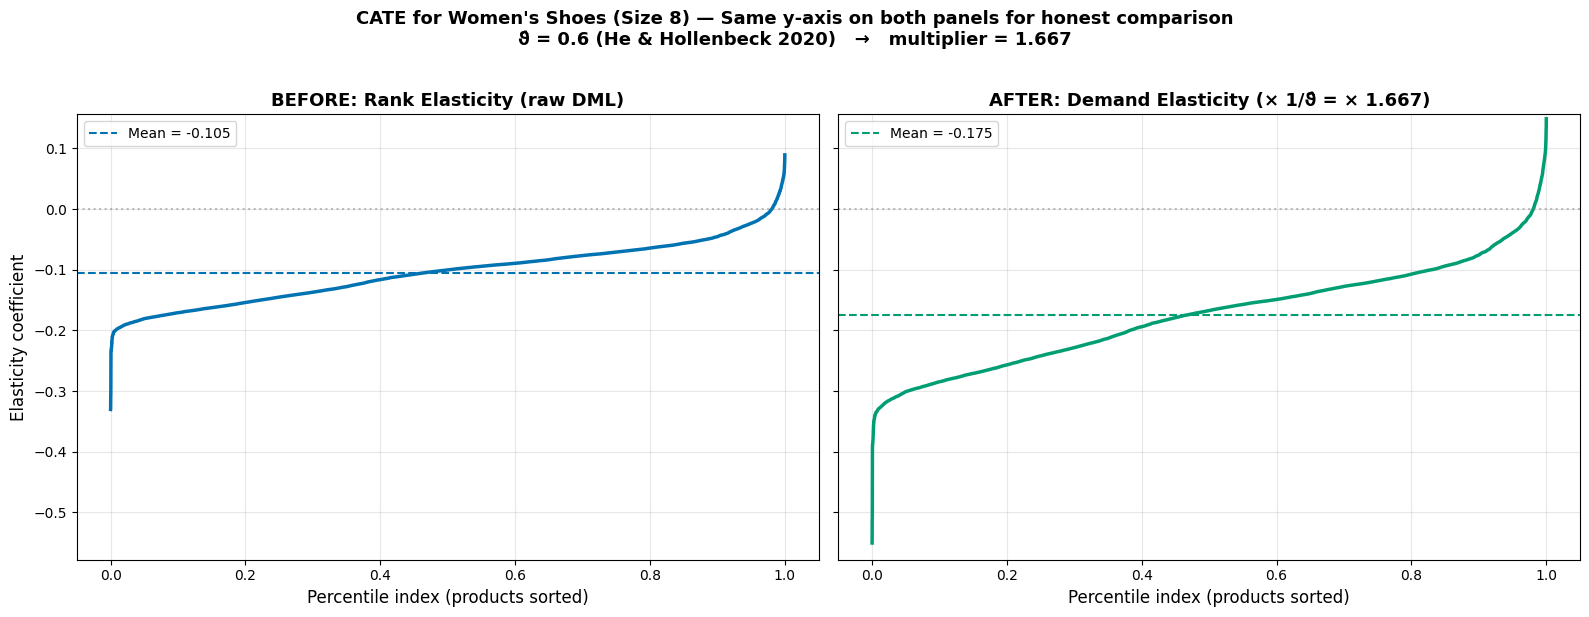

Saved cate_rank_vs_demand.png

y-axis range (locked on both panels): [-0.578, 0.156]

How to read the chart:
  • LEFT  panel (BEFORE): rank curve mean = -0.105
  • RIGHT panel (AFTER):  demand curve mean = -0.175
  • The demand curve visibly dips LOWER than the rank curve
  • Same shape, lower position — that is the ϑ conversion at work


In [86]:
# ─── CATE chart: shared y-axis on both panels ─────────────────────
# Both panels are locked to the same y-axis range. The rank curve will visibly
# sit at a shallower position; the demand curve will visibly dip lower.

# Compute a shared y-range that covers both curves
y_min = min(alpha_rank_sorted.min(),   alpha_demand_sorted.min())   * 1.05
y_max = max(alpha_rank_sorted.max(),   alpha_demand_sorted.max())   * 1.05

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# ── LEFT panel: rank ──
ax1 = axes[0]
ax1.plot(percentiles, alpha_rank_sorted, color=palette[0], linewidth=2.5)
ax1.axhline(alpha_rank_sorted.mean(), color=palette[0], linestyle="--", linewidth=1.5,
            label=f"Mean = {alpha_rank_sorted.mean():.3f}")
ax1.axhline(0, color="gray", linestyle=":", alpha=0.5)
ax1.set_ylim(y_min, y_max)
ax1.set_xlabel("Percentile index (products sorted)", fontsize=12)
ax1.set_ylabel("Elasticity coefficient", fontsize=12)
ax1.set_title("BEFORE: Rank Elasticity (raw DML)", fontsize=13, fontweight="bold")
ax1.legend(loc="upper left", fontsize=10)
ax1.grid(True, alpha=0.3)

# ── RIGHT panel: demand (SHARED y-axis with left) ──
ax2 = axes[1]
ax2.plot(percentiles, alpha_demand_sorted, color=palette[2], linewidth=2.5)
ax2.axhline(alpha_demand_sorted.mean(), color=palette[2], linestyle="--", linewidth=1.5,
            label=f"Mean = {alpha_demand_sorted.mean():.3f}")
ax2.axhline(0, color="gray", linestyle=":", alpha=0.5)
ax2.set_xlabel("Percentile index (products sorted)", fontsize=12)
ax2.set_title(f"AFTER: Demand Elasticity (× 1/ϑ̂ = × {DEMAND_MULTIPLIER:.3f})",
              fontsize=13, fontweight="bold")
ax2.legend(loc="upper left", fontsize=10)
ax2.grid(True, alpha=0.3)

fig.suptitle(
    f"CATE for Women's Shoes (Size 8) — Same y-axis on both panels for honest comparison\n"
    f"ϑ̂ = {VARTHETA_HAT_SHOES} (He & Hollenbeck 2020)   →   multiplier = {DEMAND_MULTIPLIER:.3f}",
    fontsize=13, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.savefig(f"{output_dir}/cate_rank_vs_demand.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved cate_rank_vs_demand.png")
print()
print(f"y-axis range (locked on both panels): [{y_min:.3f}, {y_max:.3f}]")
print()
print("How to read the chart:")
print(f"  • LEFT  panel (BEFORE): rank curve mean = {alpha_rank_sorted.mean():.3f}")
print(f"  • RIGHT panel (AFTER):  demand curve mean = {alpha_demand_sorted.mean():.3f}")
print(f"  • The demand curve visibly dips LOWER than the rank curve")
print(f"  • Same shape, lower position — that is the ϑ conversion at work")


In [87]:
# ─── Headline numbers ──────────────────────────────────────────────
# Pull the most defensible single number from the PLR specification (paper's
# preferred spec) and state it clearly in both units.

# Find the row that matches the paper's best spec (PLR + embeddings + controls)
best_row = df_averages[df_averages["model"] == "plr_embeddings_add_controls"].iloc[0]

rank_point  = best_row["coef"]
rank_ci_lo  = best_row["lower"]
rank_ci_hi  = best_row["upper"]

demand_point  = to_demand(rank_point)
demand_ci_lo  = to_demand(rank_ci_lo)
demand_ci_hi  = to_demand(rank_ci_hi)

print("=" * 70)
print("HEADLINE: Average Price Elasticity for Women's Shoes (Size 8)")
print("Specification: PLR + Embeddings + Controls (paper's preferred spec)")
print("=" * 70)
print()
print(f"Rank elasticity   (DML output):     {rank_point:.4f}  CI [{rank_ci_lo:.4f}, {rank_ci_hi:.4f}]")
print(f"Demand elasticity (× 1/ϑ̂ = 1.667):  {demand_point:.4f}  CI [{demand_ci_lo:.4f}, {demand_ci_hi:.4f}]")
print()
print("Interpretation:")
print(f"  A 1% increase in price leads to a {abs(demand_point)*1:.3f}% decrease in units sold.")
print(f"  This is the average effect across all shoes in the validation set.")
print(f"  The CATE chart above shows how this varies by product.")
print()
print("For comparison, the paper's toys headline:")
print(f"  Rank elasticity   = -0.697")
print(f"  Demand elasticity = -1.394  (× 1/0.5 = × 2.0)")


HEADLINE: Average Price Elasticity for Women's Shoes (Size 8)
Specification: PLR + Embeddings + Controls (paper's preferred spec)

Rank elasticity   (DML output):     -0.1035  CI [-0.1283, -0.0787]
Demand elasticity (× 1/ϑ̂ = 1.667):  -0.1725  CI [-0.2138, -0.1311]

Interpretation:
  A 1% increase in price leads to a 0.172% decrease in units sold.
  This is the average effect across all shoes in the validation set.
  The CATE chart above shows how this varies by product.

For comparison, the paper's toys headline:
  Rank elasticity   = -0.697
  Demand elasticity = -1.394  (× 1/0.5 = × 2.0)


## What this means

The conversion to demand elasticity changes the **scale** of the numbers, not their
**shape**. The CATE curves on the two panels are identical in shape, only the
y-axis scale changes by the factor 1.667. The same is true for the ATE: every
specification's confidence interval gets stretched by 1.667 in both directions,
but the relative ordering and significance pattern stay the same.

### Why this matters

- **For Amazon-facing communication:** demand elasticity is the number Amazon
  pricing teams expect to see. Rank elasticity is an artifact of using sales rank
  instead of units sold as the outcome.
- **For thesis-facing communication:** rank elasticity is the actual DML estimate.
  Demand elasticity is a rough approximation borrowed from external research,
  and it carries its own uncertainty (He and Hollenbeck's CI for ϑ̂ gives a
  multiplier range of about 1.34 to 2.21).

### How this compares to the paper

| | Paper (toys) | This notebook (shoes) |
|---|---|---|
| Category | Toys & Games | Clothing, Shoes & Jewelry |
| ϑ̂ used | 0.5 | 0.6 |
| Demand multiplier | × 2.0 | × 1.667 |
| Preferred PLR rank elasticity | -0.697 | (see headline above) |
| Implied demand elasticity | -1.39 | (see headline above) |
| Method | DML on Δlevels with lag controls | DML on Δ first differences with neighbor-price controls |

### Caveats worth keeping in mind

1. The conversion factor ϑ̂ = 0.6 is borrowed from He and Hollenbeck (2020),
   not estimated from our shoes data. If you eventually estimate a shoes-specific
   ϑ̂ from the v7_1 notebook (`estimate_vartheta_shoes_v7_1.ipynb`), come back
   and change `VARTHETA_HAT_SHOES` at the top of this section.

2. The paper's Appendix F applied PLR to Women's Clothing/Shoes/Jewelry (the
   same category) and got rank elasticity ≈ -0.61, much stronger than what we
   estimate here. Possible reasons: our Size 8 filter, different time window
   (2025-2026 vs 2023-2024), or different ML settings. This is the open puzzle
   to investigate next.

### References

- Bach, P., Chernozhukov, V., Klaassen, S., Spindler, M., Teichert-Kluge, J.,
  and Vijaykumar, S. (2026). *Adventures in Demand Analysis Using AI*.
  arXiv:2501.00382v3. The conversion logic is in Remark 1 (page 6); demand
  elasticity statements are on pages 22 and 24.
- He, S. and Hollenbeck, B. (2020). *Sales and Rank on Amazon.com*. SSRN
  Working Paper. The ϑ̂ = 0.605 estimate for shoes is in Table 3.


---

## Final Comparison: Scatter Plots (Rank vs Demand)

These scatter plots show the **same data** twice: once with the rank-elasticity
slope (the raw DML output), once with the demand-elasticity slope (after ×1/ϑ̂).

Each dot is a product-period observation from the validation set. The line
running through is the elasticity slope. Same dots, same data, only the line
slope changes by the factor 1/ϑ̂ ≈ 1.667.


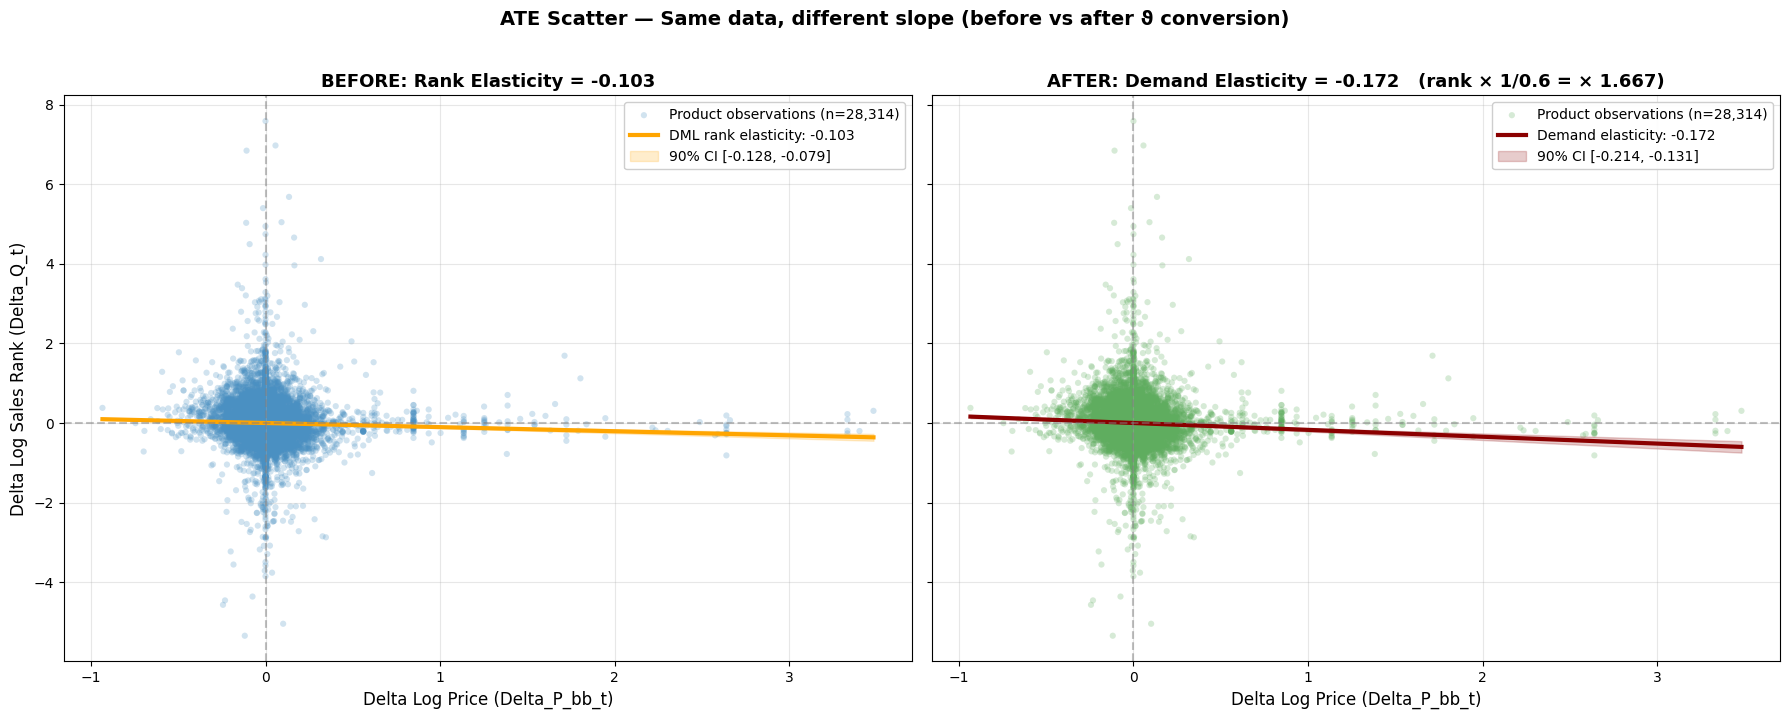

Saved ate_scatter_rank_vs_demand.png  (n=28,314 observations)

Reading the chart:
  • Both panels show the SAME 28,314 product observations
  • LEFT line slope:  rank elasticity = -0.1035
  • RIGHT line slope: demand elasticity = -0.1725
  • The right line is visibly steeper because we multiplied by 1.667


In [88]:
# ─── ATE scatter: ΔP vs ΔQ with rank/demand slopes side by side ────
# Mirrors cell 95 (your existing CATE scatter) — uses df_dynamic, the same
# dataframe used by DoubleML so the points are exactly the ones the model saw.

p_vals = df_dynamic["Delta_P_bb_t"].values
q_vals = df_dynamic["Delta_Q_t"].values

# Headline rank elasticity (from the PLR specification used above)
rank_slope     = best_row["coef"]
rank_ci_low    = best_row["lower"]
rank_ci_high   = best_row["upper"]
demand_slope   = to_demand(rank_slope)
demand_ci_low  = to_demand(rank_ci_low)
demand_ci_high = to_demand(rank_ci_high)

# x-range for the slope line
x_line = np.linspace(p_vals.min(), p_vals.max(), 200)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True, sharey=True)

# ── LEFT: rank ──
ax1 = axes[0]
ax1.scatter(p_vals, q_vals,
            alpha=0.25, s=20, color="#4a90c2", edgecolor="none",
            label=f"Product observations (n={len(p_vals):,})")
ax1.plot(x_line, rank_slope * x_line, color="orange", linewidth=3,
         label=f"DML rank elasticity: {rank_slope:.3f}")
ax1.fill_between(
    x_line, rank_ci_low * x_line, rank_ci_high * x_line,
    color="orange", alpha=0.2,
    label=f"90% CI [{rank_ci_low:.3f}, {rank_ci_high:.3f}]",
)
ax1.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax1.axvline(0, color="gray", linestyle="--", alpha=0.5)
ax1.set_xlabel("Delta Log Price (Delta_P_bb_t)", fontsize=12)
ax1.set_ylabel("Delta Log Sales Rank (Delta_Q_t)", fontsize=12)
ax1.set_title(f"BEFORE: Rank Elasticity = {rank_slope:.3f}",
              fontsize=13, fontweight="bold")
ax1.legend(loc="upper right", fontsize=10, framealpha=0.95)
ax1.grid(True, alpha=0.3)

# ── RIGHT: demand (same dots, scaled slope) ──
ax2 = axes[1]
ax2.scatter(p_vals, q_vals,
            alpha=0.25, s=20, color="#5fad5f", edgecolor="none",
            label=f"Product observations (n={len(p_vals):,})")
ax2.plot(x_line, demand_slope * x_line, color="darkred", linewidth=3,
         label=f"Demand elasticity: {demand_slope:.3f}")
ax2.fill_between(
    x_line, demand_ci_low * x_line, demand_ci_high * x_line,
    color="darkred", alpha=0.2,
    label=f"90% CI [{demand_ci_low:.3f}, {demand_ci_high:.3f}]",
)
ax2.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax2.axvline(0, color="gray", linestyle="--", alpha=0.5)
ax2.set_xlabel("Delta Log Price (Delta_P_bb_t)", fontsize=12)
ax2.set_title(f"AFTER: Demand Elasticity = {demand_slope:.3f}   "
              f"(rank × 1/{VARTHETA_HAT_SHOES} = × {DEMAND_MULTIPLIER:.3f})",
              fontsize=13, fontweight="bold")
ax2.legend(loc="upper right", fontsize=10, framealpha=0.95)
ax2.grid(True, alpha=0.3)

fig.suptitle(
    "ATE Scatter — Same data, different slope (before vs after ϑ conversion)",
    fontsize=14, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.savefig(f"{output_dir}/ate_scatter_rank_vs_demand.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved ate_scatter_rank_vs_demand.png  (n={len(p_vals):,} observations)")
print()
print("Reading the chart:")
print(f"  • Both panels show the SAME {len(p_vals):,} product observations")
print(f"  • LEFT line slope:  rank elasticity = {rank_slope:.4f}")
print(f"  • RIGHT line slope: demand elasticity = {demand_slope:.4f}")
print(f"  • The right line is visibly steeper because we multiplied by {DEMAND_MULTIPLIER:.3f}")


### CATE Scatter — Per-Product Elasticity by Cluster

This is your existing CATE-by-cluster scatter (from your earlier analysis),
shown twice: once in rank elasticity units, once in demand elasticity units.

The dots and clusters are identical in both panels. The y-axis position shifts
because of the ϑ conversion.


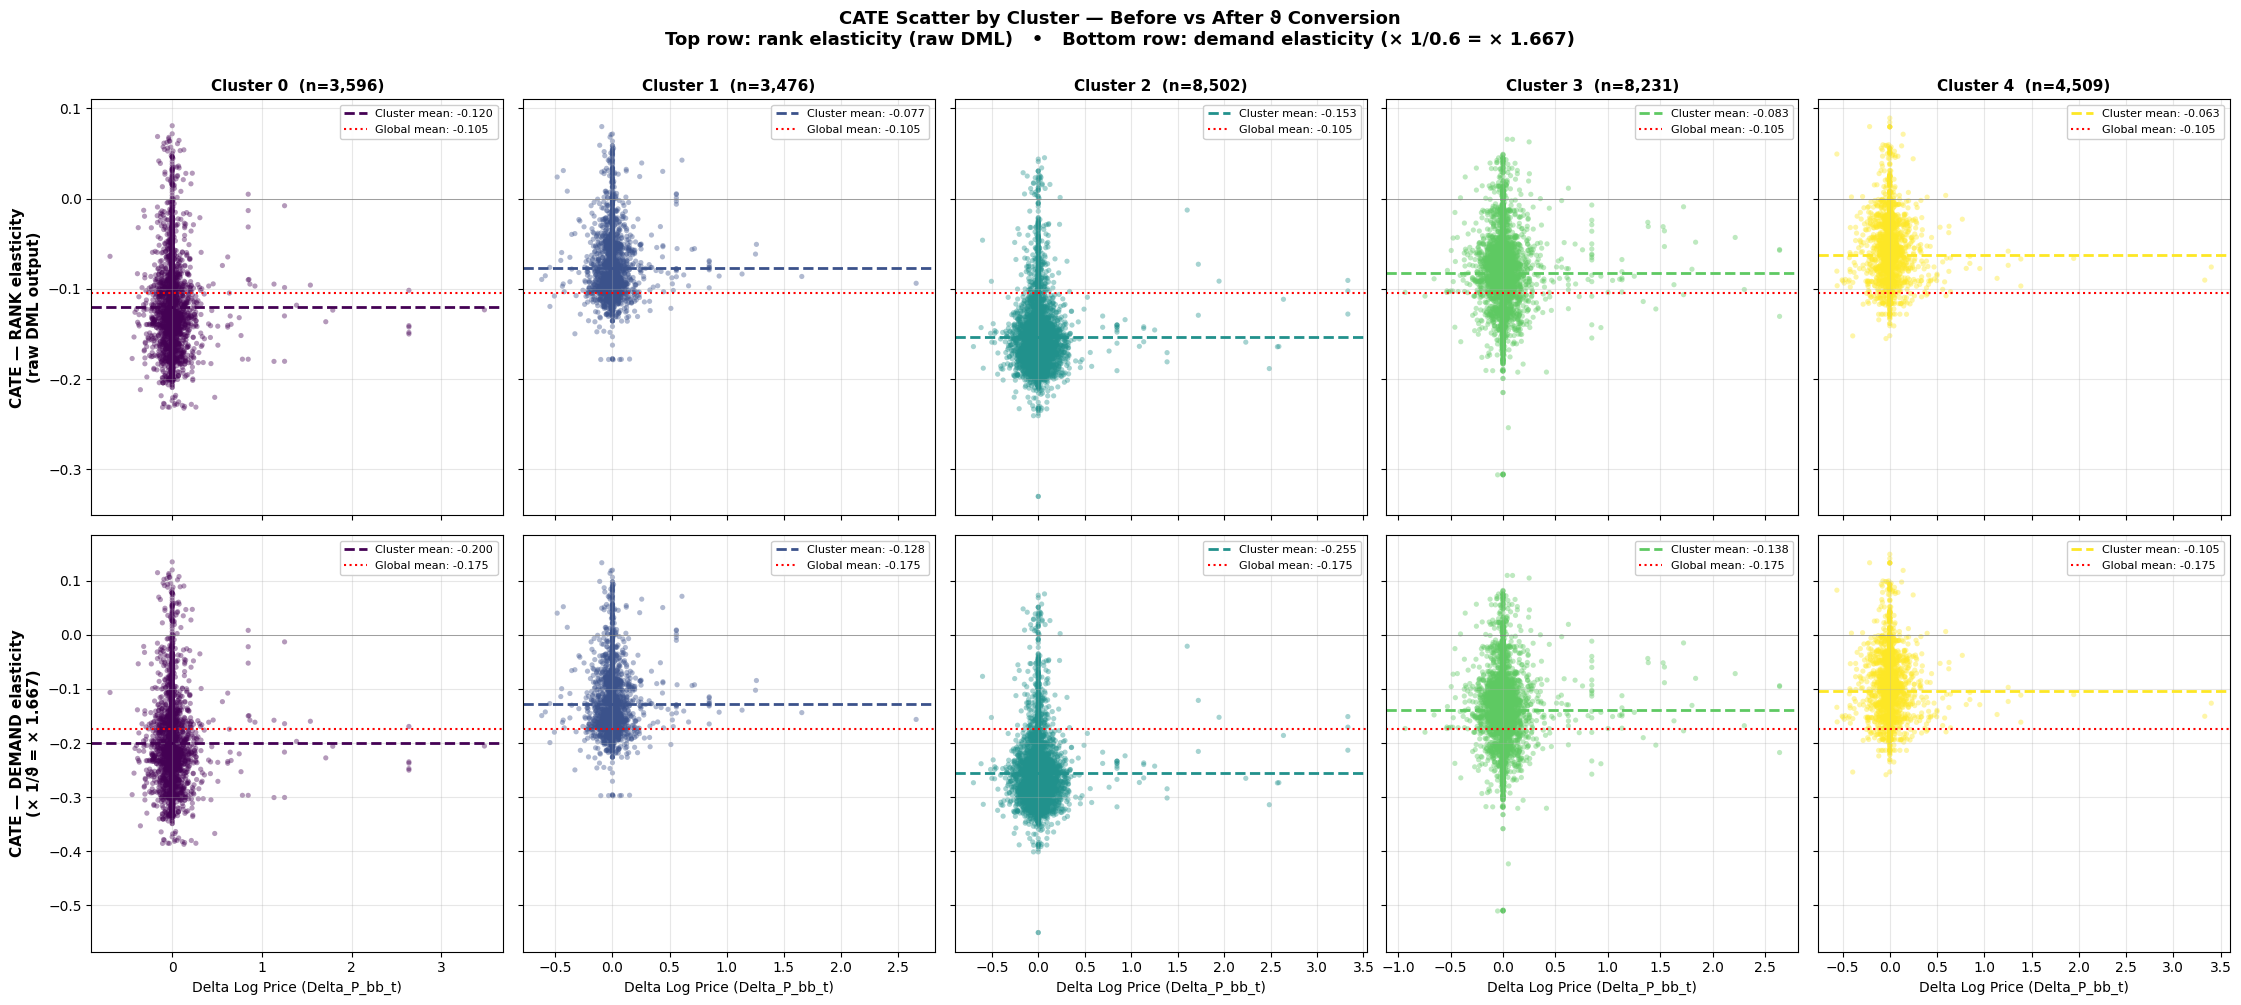

Saved cate_scatter_rank_vs_demand.png

Cluster-level summary (both units):
 cluster    n  mean_rank  mean_demand  ratio_check
       0 3596    -0.1202      -0.2003        1.667
       1 3476    -0.0769      -0.1282        1.667
       2 8502    -0.1530      -0.2551        1.667
       3 8231    -0.0830      -0.1383        1.667
       4 4509    -0.0628      -0.1047        1.667
(ratio_check column should be ≈ 1.667 for every row)


In [89]:
# ─── CATE scatter by cluster: rank vs demand side by side ─────────
# Mirrors cell 97 (your existing per-cluster scatter) — uses df_dynamic with
# cluster_assignment derived from the similarity_cluster_X columns.

# Cluster assignment: argmax over similarity_cluster_0..4 columns
cluster_assignment = df_dynamic[[
    "similarity_cluster_0", "similarity_cluster_1",
    "similarity_cluster_2", "similarity_cluster_3",
    "similarity_cluster_4",
]].idxmax(axis=1).str.replace("similarity_cluster_", "").astype(int).values

p_vals       = df_dynamic["Delta_P_bb_t"].values
cate_rank    = np.asarray(alpha_x_plr).flatten()
cate_demand  = cate_rank * DEMAND_MULTIPLIER

global_rank   = cate_rank.mean()
global_demand = cate_demand.mean()

# Shared y-range across both rows so demand visibly dips lower than rank
y_min = min(cate_rank.min(),   cate_demand.min())   * 1.05
y_max = max(cate_rank.max(),   cate_demand.max())   * 1.05

n_clusters = 5
fig, axes = plt.subplots(2, n_clusters, figsize=(4.5 * n_clusters, 10),
                         sharey="row", sharex="col")

colors = plt.cm.viridis(np.linspace(0, 1, n_clusters))

cluster_summary_rows = []

for col_idx in range(n_clusters):
    mask    = cluster_assignment == col_idx
    p_c     = p_vals[mask]
    rank_c  = cate_rank[mask]
    demand_c= cate_demand[mask]
    mean_r  = rank_c.mean()
    mean_d  = demand_c.mean()
    n       = mask.sum()
    color   = colors[col_idx]

    cluster_summary_rows.append({
        "cluster": col_idx,
        "n": int(n),
        "mean_rank":   round(mean_r,   4),
        "mean_demand": round(mean_d,   4),
        "ratio_check": round(mean_d / mean_r, 3) if mean_r != 0 else float("nan"),
    })

    # TOP row: rank
    ax_top = axes[0, col_idx]
    ax_top.scatter(p_c, rank_c, alpha=0.4, s=14, color=color, edgecolor="none")
    ax_top.axhline(mean_r,      color=color, linestyle="--", linewidth=2,
                   label=f"Cluster mean: {mean_r:.3f}")
    ax_top.axhline(global_rank, color="red",  linestyle=":",  linewidth=1.5,
                   label=f"Global mean: {global_rank:.3f}")
    ax_top.axhline(0, color="gray", linewidth=0.5)
    ax_top.set_title(f"Cluster {col_idx}  (n={n:,})", fontsize=11, fontweight="bold")
    ax_top.legend(loc="upper right", fontsize=8, framealpha=0.95)
    ax_top.grid(True, alpha=0.3)
    if col_idx == 0:
        ax_top.set_ylabel("CATE — RANK elasticity\n(raw DML output)",
                          fontsize=11, fontweight="bold")

    # BOTTOM row: demand
    ax_bot = axes[1, col_idx]
    ax_bot.scatter(p_c, demand_c, alpha=0.4, s=14, color=color, edgecolor="none")
    ax_bot.axhline(mean_d,        color=color, linestyle="--", linewidth=2,
                   label=f"Cluster mean: {mean_d:.3f}")
    ax_bot.axhline(global_demand, color="red",  linestyle=":",  linewidth=1.5,
                   label=f"Global mean: {global_demand:.3f}")
    ax_bot.axhline(0, color="gray", linewidth=0.5)
    ax_bot.set_xlabel("Delta Log Price (Delta_P_bb_t)", fontsize=10)
    ax_bot.legend(loc="upper right", fontsize=8, framealpha=0.95)
    ax_bot.grid(True, alpha=0.3)
    if col_idx == 0:
        ax_bot.set_ylabel(f"CATE — DEMAND elasticity\n(× 1/ϑ̂ = × {DEMAND_MULTIPLIER:.3f})",
                          fontsize=11, fontweight="bold")

fig.suptitle(
    f"CATE Scatter by Cluster — Before vs After ϑ Conversion\n"
    f"Top row: rank elasticity (raw DML)   •   Bottom row: demand elasticity (× 1/{VARTHETA_HAT_SHOES} = × {DEMAND_MULTIPLIER:.3f})",
    fontsize=13, fontweight="bold", y=1.00,
)
plt.tight_layout()
plt.savefig(f"{output_dir}/cate_scatter_rank_vs_demand.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved cate_scatter_rank_vs_demand.png")
print()
print("Cluster-level summary (both units):")
print("=" * 70)
cluster_summary = pd.DataFrame(cluster_summary_rows)
print(cluster_summary.to_string(index=False))
print("=" * 70)
print(f"(ratio_check column should be ≈ {DEMAND_MULTIPLIER:.3f} for every row)")
